# Computational checks for Bayesian subspace tracking

The [beamforming](01_array.ipynb) and [contact-normal](03_contact.ipynb) notebooks explain the applications. This supplement follows the computational chain behind them: normalized likelihood, information, finite-data curvature, tracking envelope, prediction, block EM, and reliability under changed noise or motion.

Figure IDs follow the implementation guide. The [claim manifest](../results/implementation_audit/claim_manifest.json) maps each requested check to its routine, metric, figure, assumptions and observed status. Exact aliases of main figures are identified in the figure manifest; an alias is not another independent experiment. The [audit note](../docs/implementation_guide_audit.md) identifies which requirements existed and which were added, including unavailable manuscript-source checks.

The guide names `main.tex` and `supplementary.tex`, which were not present in the supplied checkout. Explicit formulas in the guide and the supplied draft are the available specification; no claim of inspecting missing source text is made. Negative, inconclusive and numerically unresolved results remain in the [findings](../results/implementation_audit/findings.md) and raw tables.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap, BoundaryNorm

ROOT = Path.cwd() if (Path.cwd() / 'lib').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from lib.plotting import plt  # Matplotlib plus the required TeX environment.
from lib.notebook_audit_data import load_audit_data, verify_audit_inputs
INPUT_HASHES = verify_audit_inputs(ROOT)
EDITABLE_OUTPUT = ROOT / 'results/notebook_exports/04_implementation_audit'
EDITABLE_OUTPUT.mkdir(parents=True, exist_ok=True)

# Shared defaults are visible here; every figure below also has local DPI and FIGSIZE.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': 11,
    'axes.labelsize': 11, 'axes.titlesize': 11, 'legend.fontsize': 10,
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'lines.linewidth': 1.6,
    'figure.dpi': 300, 'savefig.dpi': 300, 'savefig.bbox': None,
    'axes.spines.top': False, 'axes.spines.right': False,
})
BLUE, PINK, ORANGE, GREY, BLACK = '#245FA8', '#D865A7', '#D55E00', '#69737D', '#252525'
CHANNELS = {'marginal_real': 'Real marginal', 'marginal_complex': 'Complex marginal', 'conditional_real': 'Real conditional', 'conditional_complex': 'Complex conditional', 'real_marginal': 'Real marginal', 'complex_marginal': 'Complex marginal', 'real_conditional': 'Real conditional', 'complex_conditional': 'Complex conditional'}
METHODS = {'mean': '$\\overline P_t^+$', 'mode': '$P_{\\widehat{\\mathcal X}_t}$', 'iso': '$\\overline P(\\kappa P_{\\widehat{\\mathcal X}_t})$', 'isotropic': '$\\overline P(\\kappa P_{\\widehat{\\mathcal X}_t})$', 'scm': 'Loaded covariance', 'lw': 'Ledoit--Wolf', 'grouse': 'GROUSE', 'known': 'Known scales', 'misspecified': 'Misspecified scales', 'block_em': 'Block EM', 'residual': 'Residual fit'}

def text_label(value):
    labels = {'beamforming': 'Beamforming', 'contact': 'Contact', 'prior_predictive': 'Prior predictive', 'fixed_state': 'Fixed state', 'drifting': 'Drifting state', 'noise_only': 'Noise changes', 'motion_only': 'Motion changes', 'matched': 'Matched model', 'desired_contamination': 'Desired signal in training', 'unequal_rank_two_powers': 'Unequal signal powers', 'anisotropic_damping': 'Anisotropic damping', 'friction': 'Friction', 'contact_loss': 'Contact loss', 'real_marginal_rank_one': 'Real marginal, $k=1$', 'real_marginal_rank_two': 'Real marginal, $k=2$', 'complex_marginal_rank_one': 'Complex marginal, $k=1$', 'conditional_contact_plane': 'Conditional contact plane'}
    return labels.get(str(value), str(value).replace('_', '\\_'))

print('Verified', len(INPUT_HASHES), 'historical input files. Plot edits do not rerun the studies.')

Verified 45 historical input files. Plot edits do not rerun the studies.


### Editing and saved evidence

Every figure below contains its complete Matplotlib drawing code. Change its `DPI`, `FIGSIZE`, axis labels, limits, colors, legends or `fig.savefig(...)` call directly, then rerun that cell. The one-line `load_audit_data(...)` call only reads and verifies the saved arrays/tables; it has no Matplotlib calls and performs no inference, fitting or simulation.

These are the original historical implementation-study fixtures. Their component-manifest table hashes are checked independently of the current application code; the historical whole-code validation gate is not claimed to certify a different source tree. The theoretical assertion cells are retained. Editable PDF exports go to `results/notebook_exports/04_implementation_audit/`, leaving the frozen scientific inputs and canonical published PDFs untouched.


## B2a; C2. From a likelihood to expected information

The real marginal model has $F=L(\tau^2)^2/[s(s+\tau^2)]I$. Proper-complex data double this coefficient in real/imaginary tangent coordinates and double the tangent dimension. The conditional calculation uses recorded inputs; it does not reconstruct an unobserved input from a measured response.

The first panel compares analytical information with empirical score covariance. The second checks expected likelihood Hessians and exact Gaussian KL curvature at several finite-difference steps. The third compares the KL contours and their local Fisher approximation in the same tangent chart. Discounted Hessians use weights $w_j$, whereas discounted score covariance uses $w_j^2$; those separate tests remain in the tables.

In [2]:
import numpy as np
from lib.beamforming_theory import passive_fisher_information
F_real = passive_fisher_information(3, 1, s=0.2, q=1.3, observations=4, complex_data=False)
F_complex = passive_fisher_information(3, 1, s=0.2, q=1.3, observations=4, complex_data=True)
assert F_complex.shape[0] == 2 * F_real.shape[0]
assert np.allclose(np.diag(F_complex), 2 * F_real[0, 0])
print('Real tangent dimension:', len(F_real), '; complex real-coordinate dimension:', len(F_complex))
print('Fisher coefficient:', F_real[0, 0], '(real),', F_complex[0, 0], '(proper complex)')

Real tangent dimension: 2 ; complex real-coordinate dimension: 4
Fisher coefficient: 22.53333333333333 (real), 45.06666666666666 (proper complex)


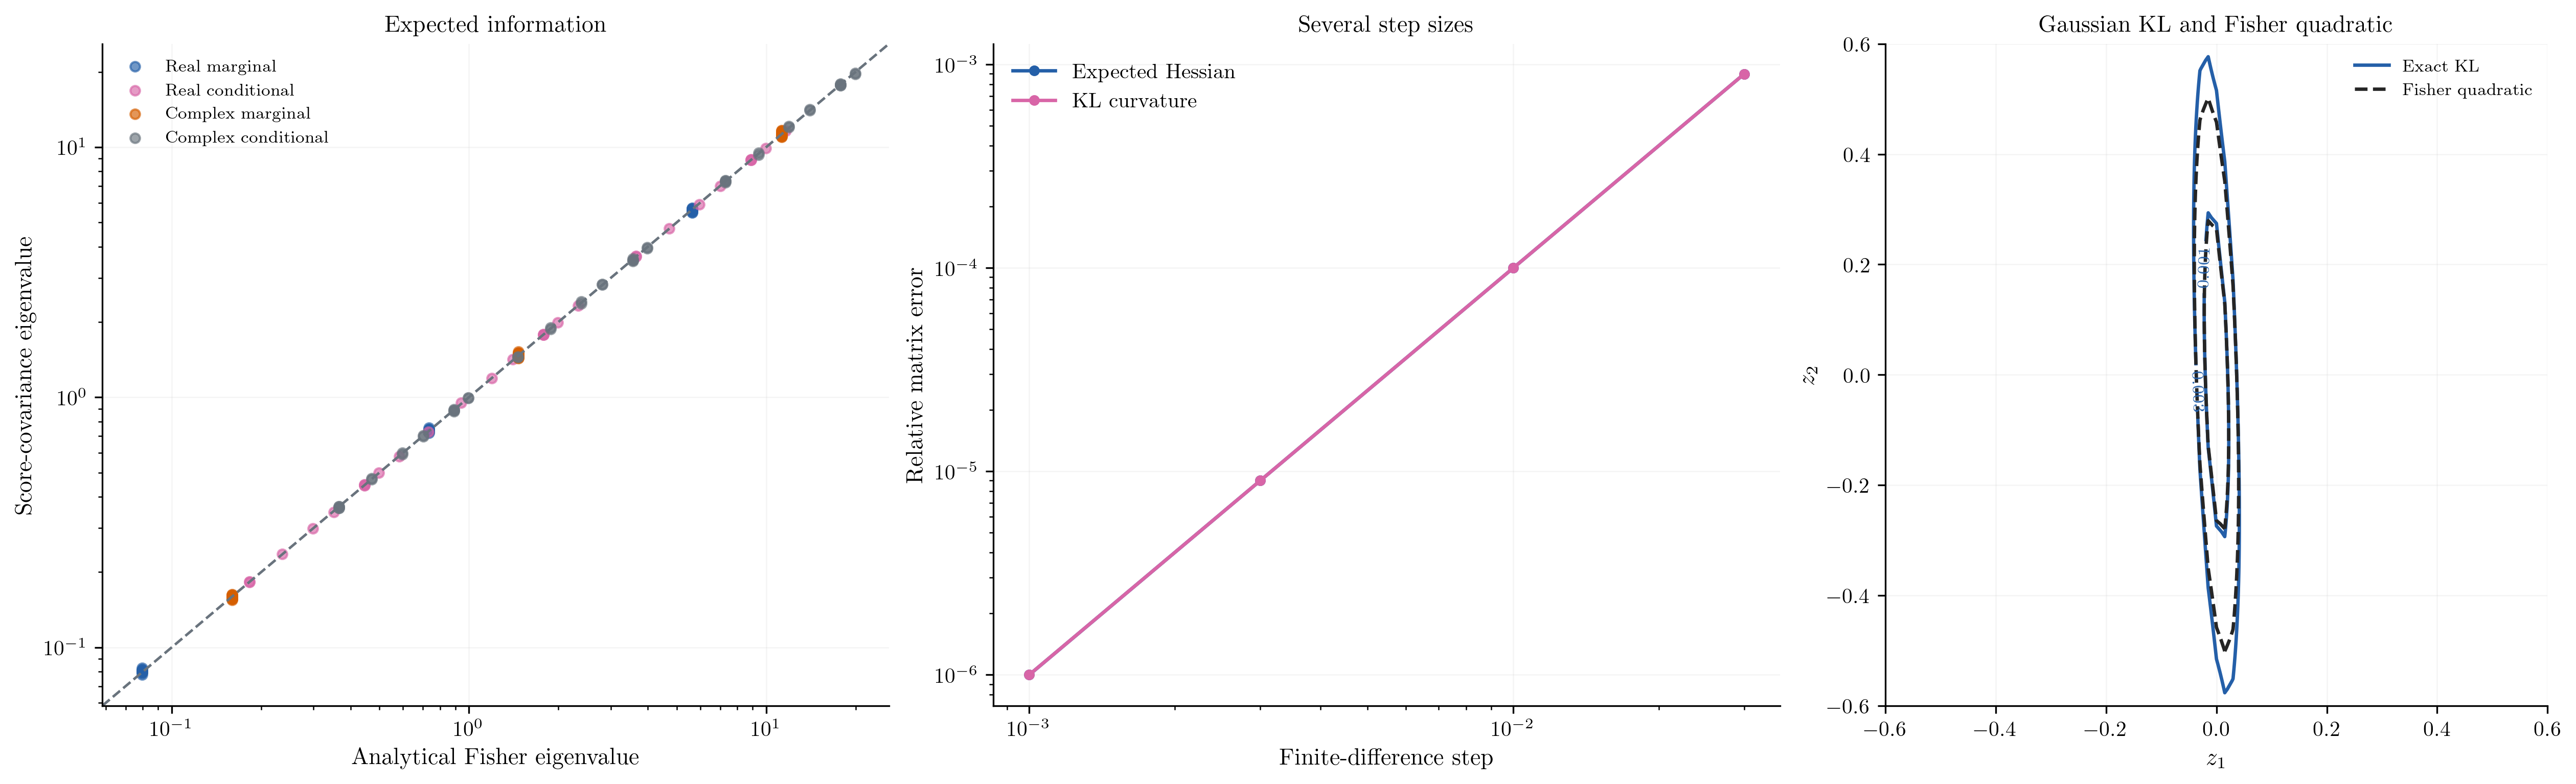

In [3]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (17, 5)
data = load_audit_data(ROOT, 'information')

frame, fd, grid = (data['fisher_matrices'], data['finite_differences'], data['kl_grid'])
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, layout='constrained', dpi=DPI)
all_x, all_y = ([], [])
for j, ((case, channel), group) in enumerate(frame.groupby(['case', 'channel'], sort=False)):
    expected = group.pivot(index='i', columns='j', values='expected').to_numpy()
    empirical = group.pivot(index='i', columns='j', values='score_covariance').to_numpy()
    x, y = (np.linalg.eigvalsh(expected), np.linalg.eigvalsh(empirical))
    label = ('Complex ' if bool(group.complex_data.iloc[0]) else 'Real ') + str(channel)
    color_index = (2 if bool(group.complex_data.iloc[0]) else 0) + (1 if str(channel) == 'conditional' else 0)
    used = axes[0].get_legend_handles_labels()[1]
    axes[0].scatter(x, y, s=20, alpha=0.65, color=(BLUE, PINK, ORANGE, GREY)[color_index], label=label if label not in used else None)
    all_x.extend(x)
    all_y.extend(y)
if np.min(all_x) > 0 and np.min(all_y) > 0:
    lo, hi = (min(all_x + all_y) * 0.75, max(all_x + all_y) * 1.3)
    axes[0].plot([lo, hi], [lo, hi], '--', color=GREY, lw=1.2)
    axes[0].set(xlim=(lo, hi), ylim=(lo, hi), xscale='log', yscale='log')
else:
    _identity_values_1 = np.r_[np.asarray(all_x, float), np.asarray(all_y, float)]
    _identity_values_1 = _identity_values_1[np.isfinite(_identity_values_1)]
    _identity_low_1, _identity_high_1 = (float(_identity_values_1.min()), float(_identity_values_1.max()))
    _identity_pad_1 = max((_identity_high_1 - _identity_low_1) * 0.06, abs(_identity_high_1) * 0.02, 1e-12)
    axes[0].plot([_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1], [_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1], '--', color=GREY, lw=1.2)
    axes[0].set(xlim=(_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1), ylim=(_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1))
    axes[0].set_xscale('symlog', linthresh=0.001)
    axes[0].set_yscale('symlog', linthresh=0.001)
axes[0].set(xlabel='Analytical Fisher eigenvalue', ylabel='Score-covariance eigenvalue', title='Expected information')
axes[0].legend(frameon=False, fontsize=8)
errors = []
for (case, channel, step), g in fd.groupby(['case', 'channel', 'step'], sort=False):
    f = g.fisher.to_numpy()
    norm = max(np.linalg.norm(f), np.finfo(float).eps)
    for column, label in [('negative_expected_hessian', 'Expected Hessian'), ('kl_hessian', 'KL curvature')]:
        errors.append((step, label, np.linalg.norm(g[column].to_numpy() - f) / norm))
errors = pd.DataFrame(errors, columns=['step', 'method', 'error'])
for color, (method, group) in zip((BLUE, PINK), errors.groupby('method', sort=False)):
    median = group.groupby('step').error.median()
    lower = group.groupby('step').error.min()
    upper = group.groupby('step').error.max()
    axes[1].loglog(median.index, np.maximum(median, 1e-16), 'o-', color=color, label=method)
    axes[1].fill_between(median.index, np.maximum(lower, 1e-16), np.maximum(upper, 1e-16), color=color, alpha=0.12)
axes[1].set(xlabel='Finite-difference step', ylabel='Relative matrix error', title='Several step sizes')
axes[1].legend(frameon=False)
names = list(map(str, grid['names']))
selected = names.index('real_conditional') if 'real_conditional' in names else 0
z = np.asarray(grid['kl'][selected])
q = np.asarray(grid['fisher_quadratic'][selected])
levels = [0.001, 0.003]
exact = axes[2].contour(grid['x'], grid['y'], z, levels=levels, colors=BLUE)
axes[2].contour(grid['x'], grid['y'], q, levels=levels, colors=BLACK, linestyles='--')
axes[2].clabel(exact, fmt='%.2g', fontsize=8)
axes[2].set(xlabel='$z_1$', ylabel='$z_2$', title='Gaussian KL and Fisher quadratic')
axes[2].set_aspect('equal', adjustable='box')
axes[2].legend(handles=[Line2D([0], [0], color=BLUE, label='Exact KL'), Line2D([0], [0], color=BLACK, ls='--', label='Fisher quadratic')], frameon=False, fontsize=8)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='both', alpha=0.13, linewidth=0.6)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'B2a_C2_information.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## B2a. Check observation count and signal-to-noise ratio separately

The next panel uses a separate declared cohort. Each episode sums its likelihood scores over $L$ independent observations; empirical covariance is then estimated across independent episodes. The reference Fisher matrix scales with $L$. A Monte Carlo draw count is not relabeled as an observation count, and posterior-curvature samples are not used as substitutes for expected information.

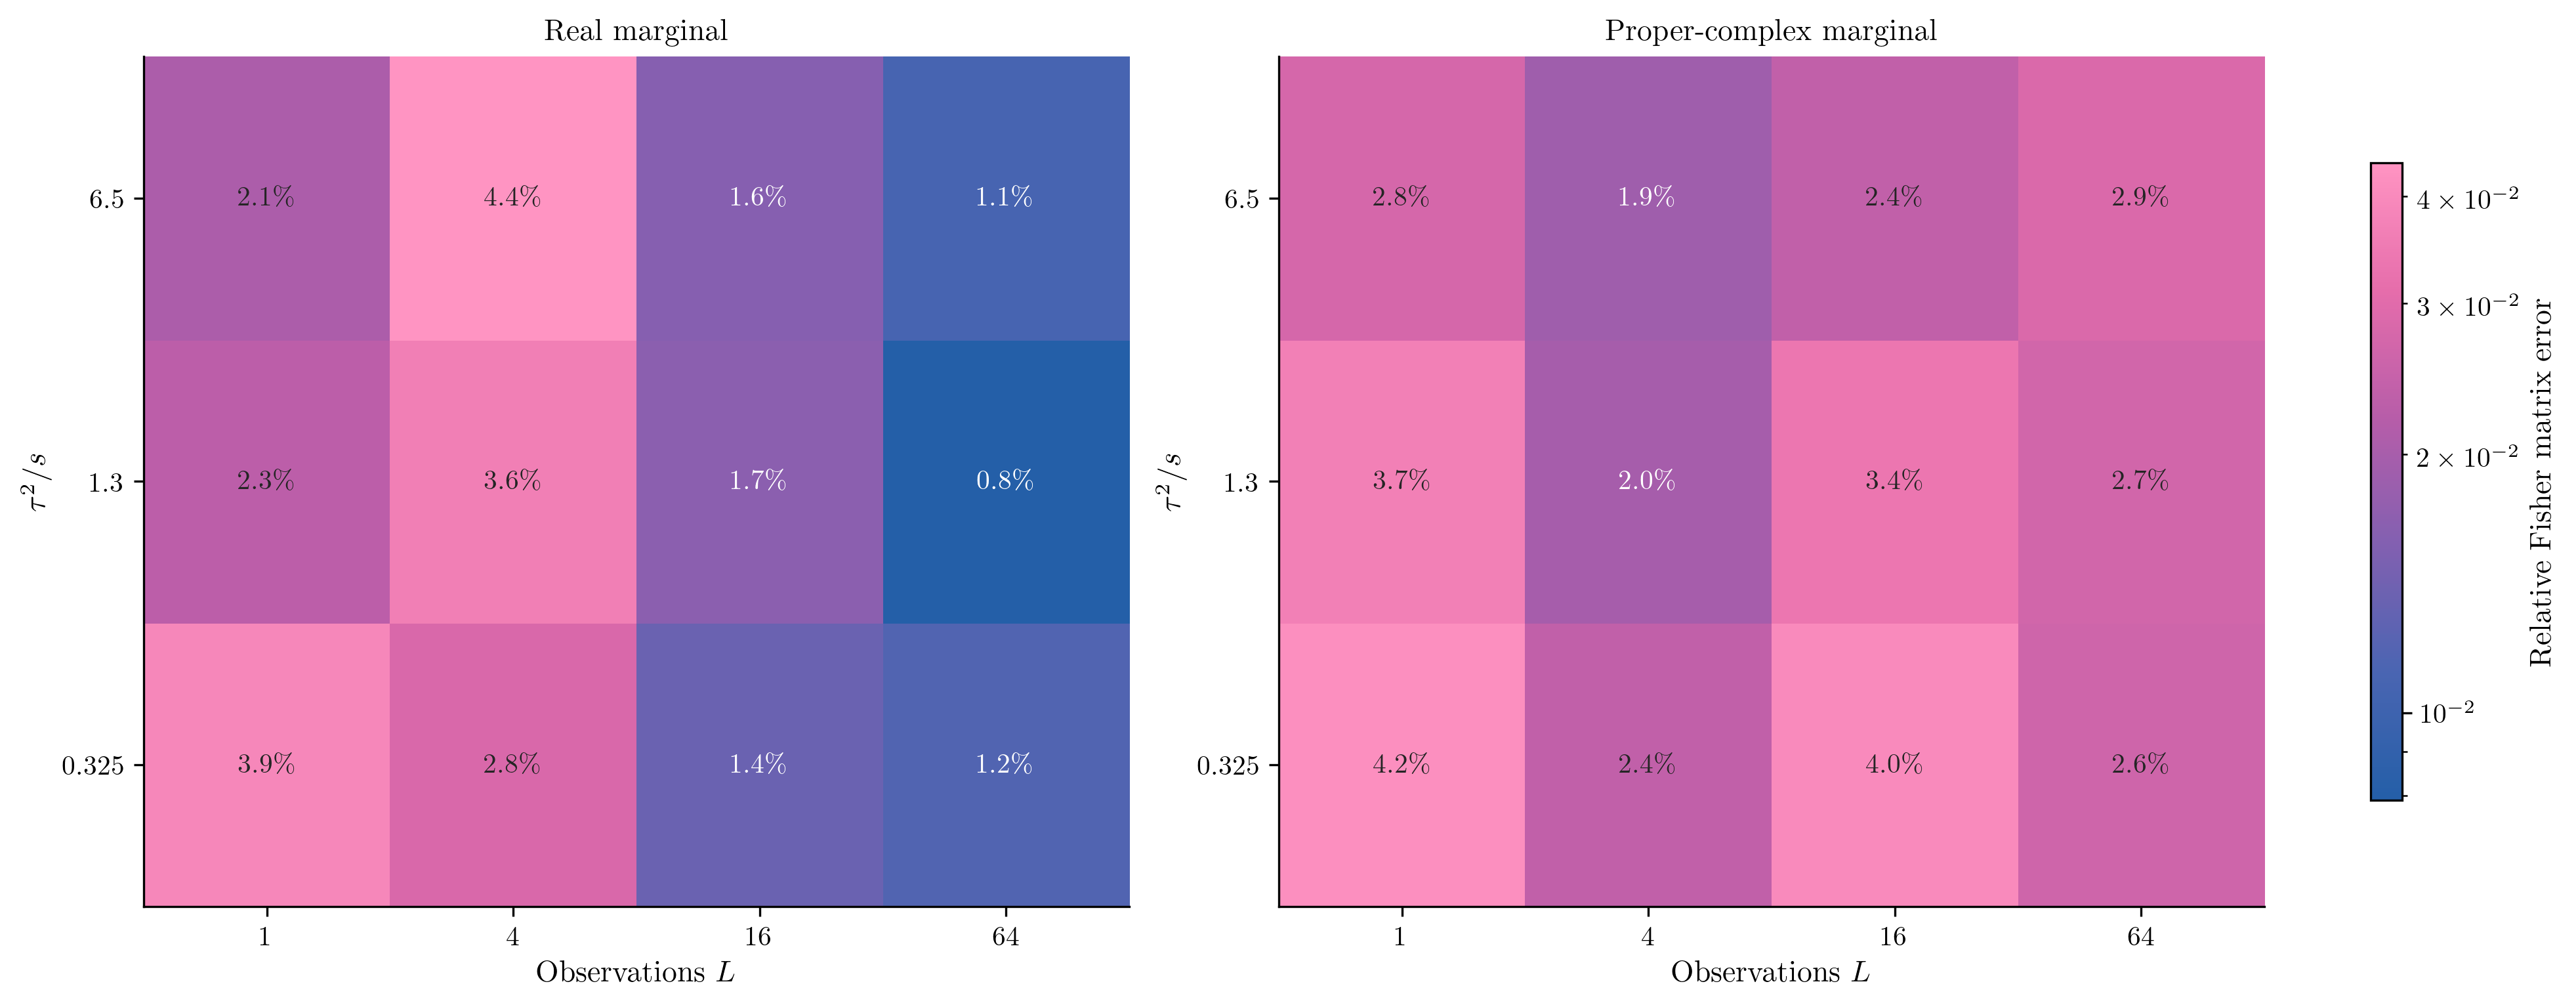

In [4]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (13, 5)
data = load_audit_data(ROOT, 'information_counts')

from matplotlib.colors import LogNorm
from matplotlib.colors import LinearSegmentedColormap
DENSITY_CMAP = LinearSegmentedColormap.from_list(
    'bingham_density_blue_pink',
    ['#245FA8', '#4A65B2', '#8260B1', '#B75DA9', '#E66DAB', '#FF94C2'], N=256)
DENSITY_CMAP.set_under('#245FA8')
DENSITY_CMAP.set_over('#FF94C2')
frame = data['summary']
positive = frame.relative_frobenius_error.to_numpy()
positive = positive[np.isfinite(positive) & (positive > 0)]
norm = LogNorm(vmin=float(positive.min()), vmax=float(positive.max()))
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, layout='constrained', dpi=DPI)
for ax, complex_data, title in zip(axes, [False, True], ['Real marginal', 'Proper-complex marginal']):
    group = frame[frame.complex_data.eq(complex_data)]
    matrix = group.pivot(index='snr', columns='observations', values='relative_frobenius_error')
    im = ax.imshow(matrix, origin='lower', aspect='auto', cmap=DENSITY_CMAP, norm=norm)
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            value = float(matrix.iloc[i, j])
            ax.text(j, i, f'{100 * value:.1f}\\%', ha='center', va='center', fontsize=10, color=BLACK if norm(value) > 0.55 else 'white')
    ax.set(xticks=np.arange(len(matrix.columns)), xticklabels=[str(v) for v in matrix.columns], yticks=np.arange(len(matrix.index)), yticklabels=[f'{v:g}' for v in matrix.index], xlabel='Observations $L$', ylabel='$\\tau^2/s$', title=title)
fig.colorbar(im, ax=axes, shrink=0.75, label='Relative Fisher matrix error')

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'B2a_count_error.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## B2b. Expected information is not realized posterior curvature

The marginal likelihood has isotropic expected information at its generating state. A finite collection of measured vectors can still produce unequal selected/complementary eigenvalue gaps. The realized negative Bingham log-density Hessian has twice those gaps in the real tangent chart. Flat directions after a small number of observations are retained.

The display fixes $N=3$ and the first declared sensor variance, then changes only the observation count. Boxes describe the spread of realized curvature eigenvalues across datasets, rather than uncertainty in a fitted regression coefficient. Posterior-mode and generating-state tangent frames are distinct, so this is an invariant spectral comparison.

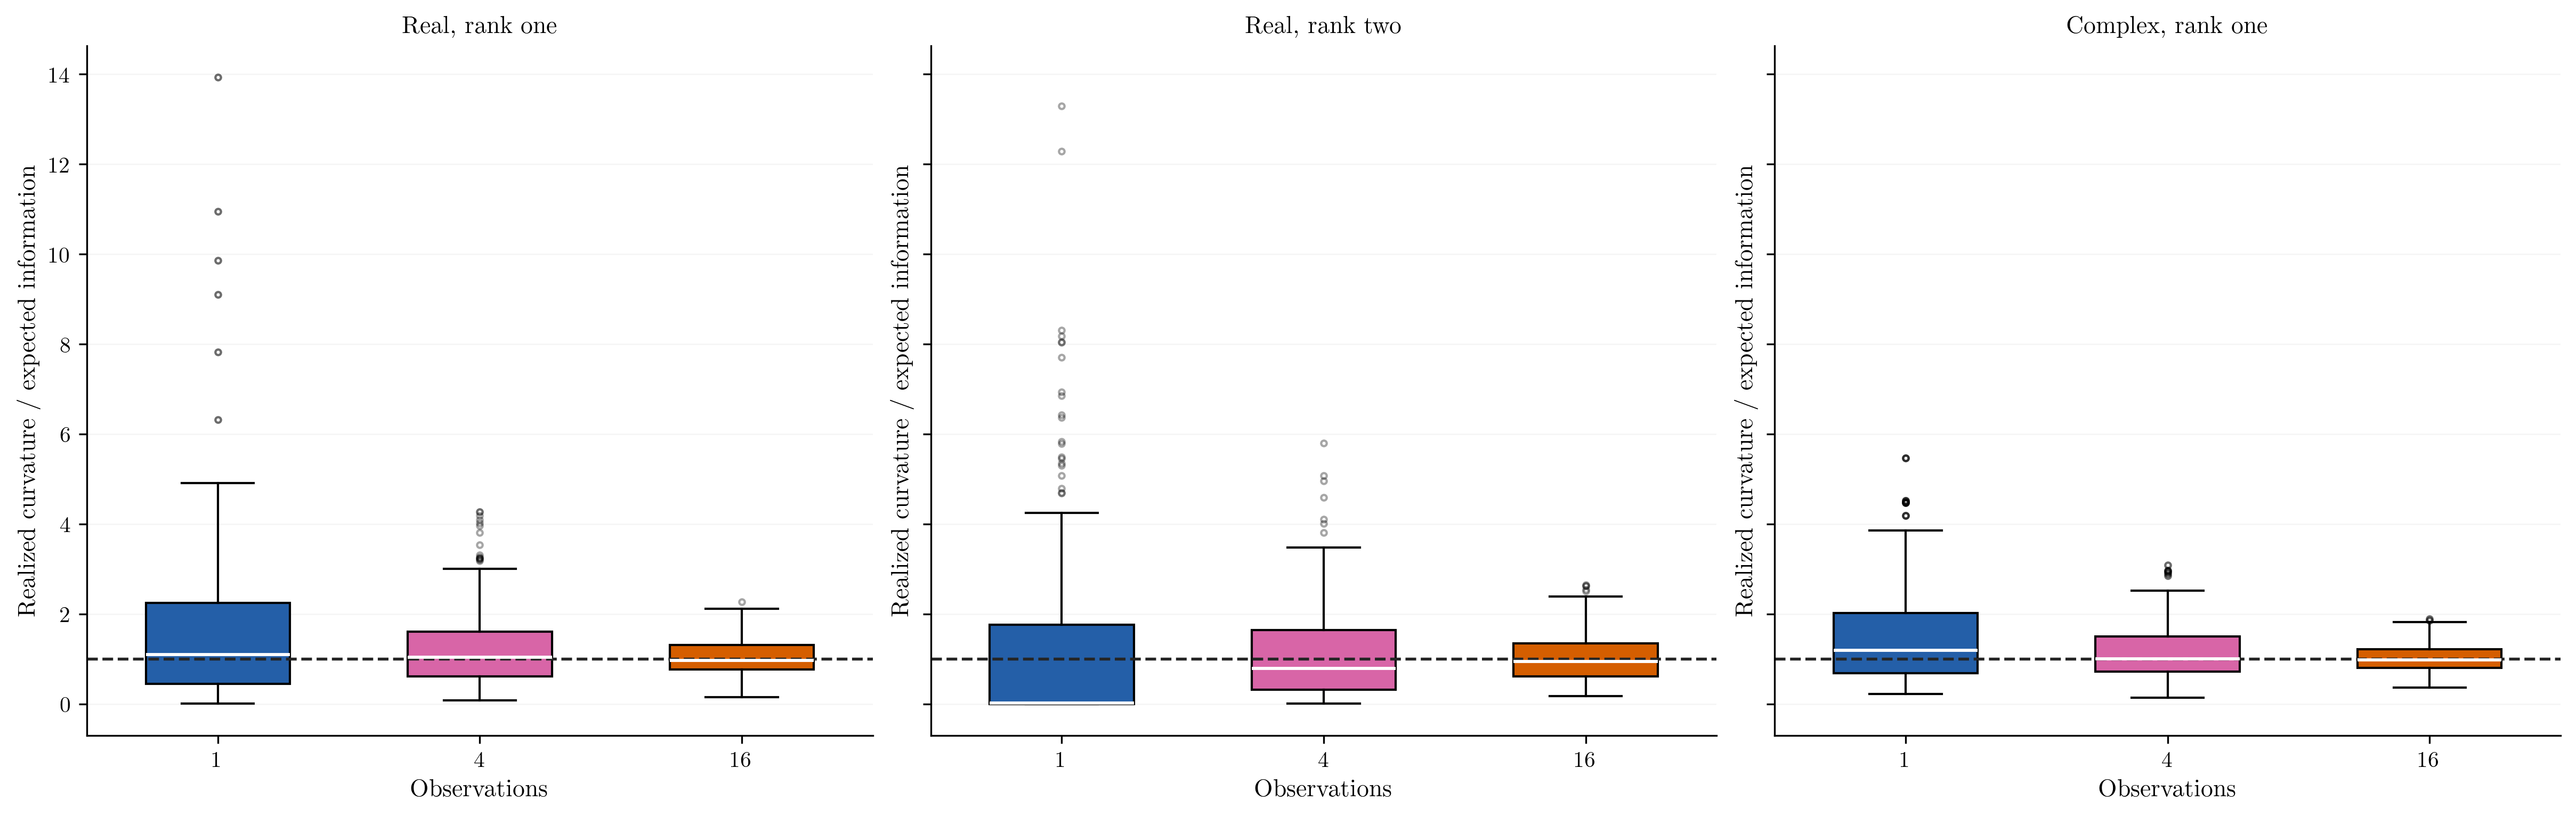

In [5]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (16, 5)
data = load_audit_data(ROOT, 'information')

frame = data['curvature']
settings = [(False, 1, 'Real, rank one'), (False, 2, 'Real, rank two'), (True, 1, 'Complex, rank one')]
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, layout='constrained', sharey=True, dpi=DPI)
for ax, (complex_data, k, title) in zip(axes, settings):
    group = frame[frame.n.eq(3) & frame.k.eq(k) & frame.complex_data.eq(complex_data)]
    group = group[np.isclose(group.s, group.s.min())]
    times = list(sorted(group.t.unique()))
    arrays = []
    for time in times:
        g = group[group.t.eq(time)]
        ratio = g.realized_curvature.to_numpy() / g.expected_information.to_numpy()
        arrays.append(ratio[np.isfinite(ratio)])
    artists = ax.boxplot(arrays, tick_labels=[str(t) for t in times], patch_artist=True, widths=0.55, medianprops={'color': 'white', 'linewidth': 1.4}, flierprops={'markersize': 2.5, 'alpha': 0.35})
    for j, box in enumerate(artists['boxes']):
        box.set_facecolor((BLUE, PINK, ORANGE)[j % 3])
    ax.axhline(1, color=BLACK, ls='--', lw=1.3)
    ax.set(xlabel='Observations', ylabel='Realized curvature / expected information', title=title)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.13, linewidth=0.6)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'B2b_posterior_curvature.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## B3; C4. When does the modal tracking theorem say something?

For real marginal data, $\eta=\tau^2/[2s(s+\tau^2)]$, $h=N\log9+\log(2/\delta)$ and $\gamma_t=\eta\tau^2m_t$. The guide uses the fluctuation allowance $4\eta(s+\tau^2)(\sqrt{b_th}+h)$, with weighted aggregate drift and the initial spectral-gauge radius. The proper-complex extension changes both $\eta$ and $h$. Conditional bounds use their separate recorded-input formula.

The reported envelope is $2\sqrt{k}\epsilon_t/\gamma_t$ only when $\epsilon_t<\gamma_t/2$. A valid sufficient condition can still give an envelope above the geometric distance ceiling. These calculations use fixed true scales, deterministic paths and fixed memory; the true gap and drift are evaluation diagnostics, not an online confidence radius.

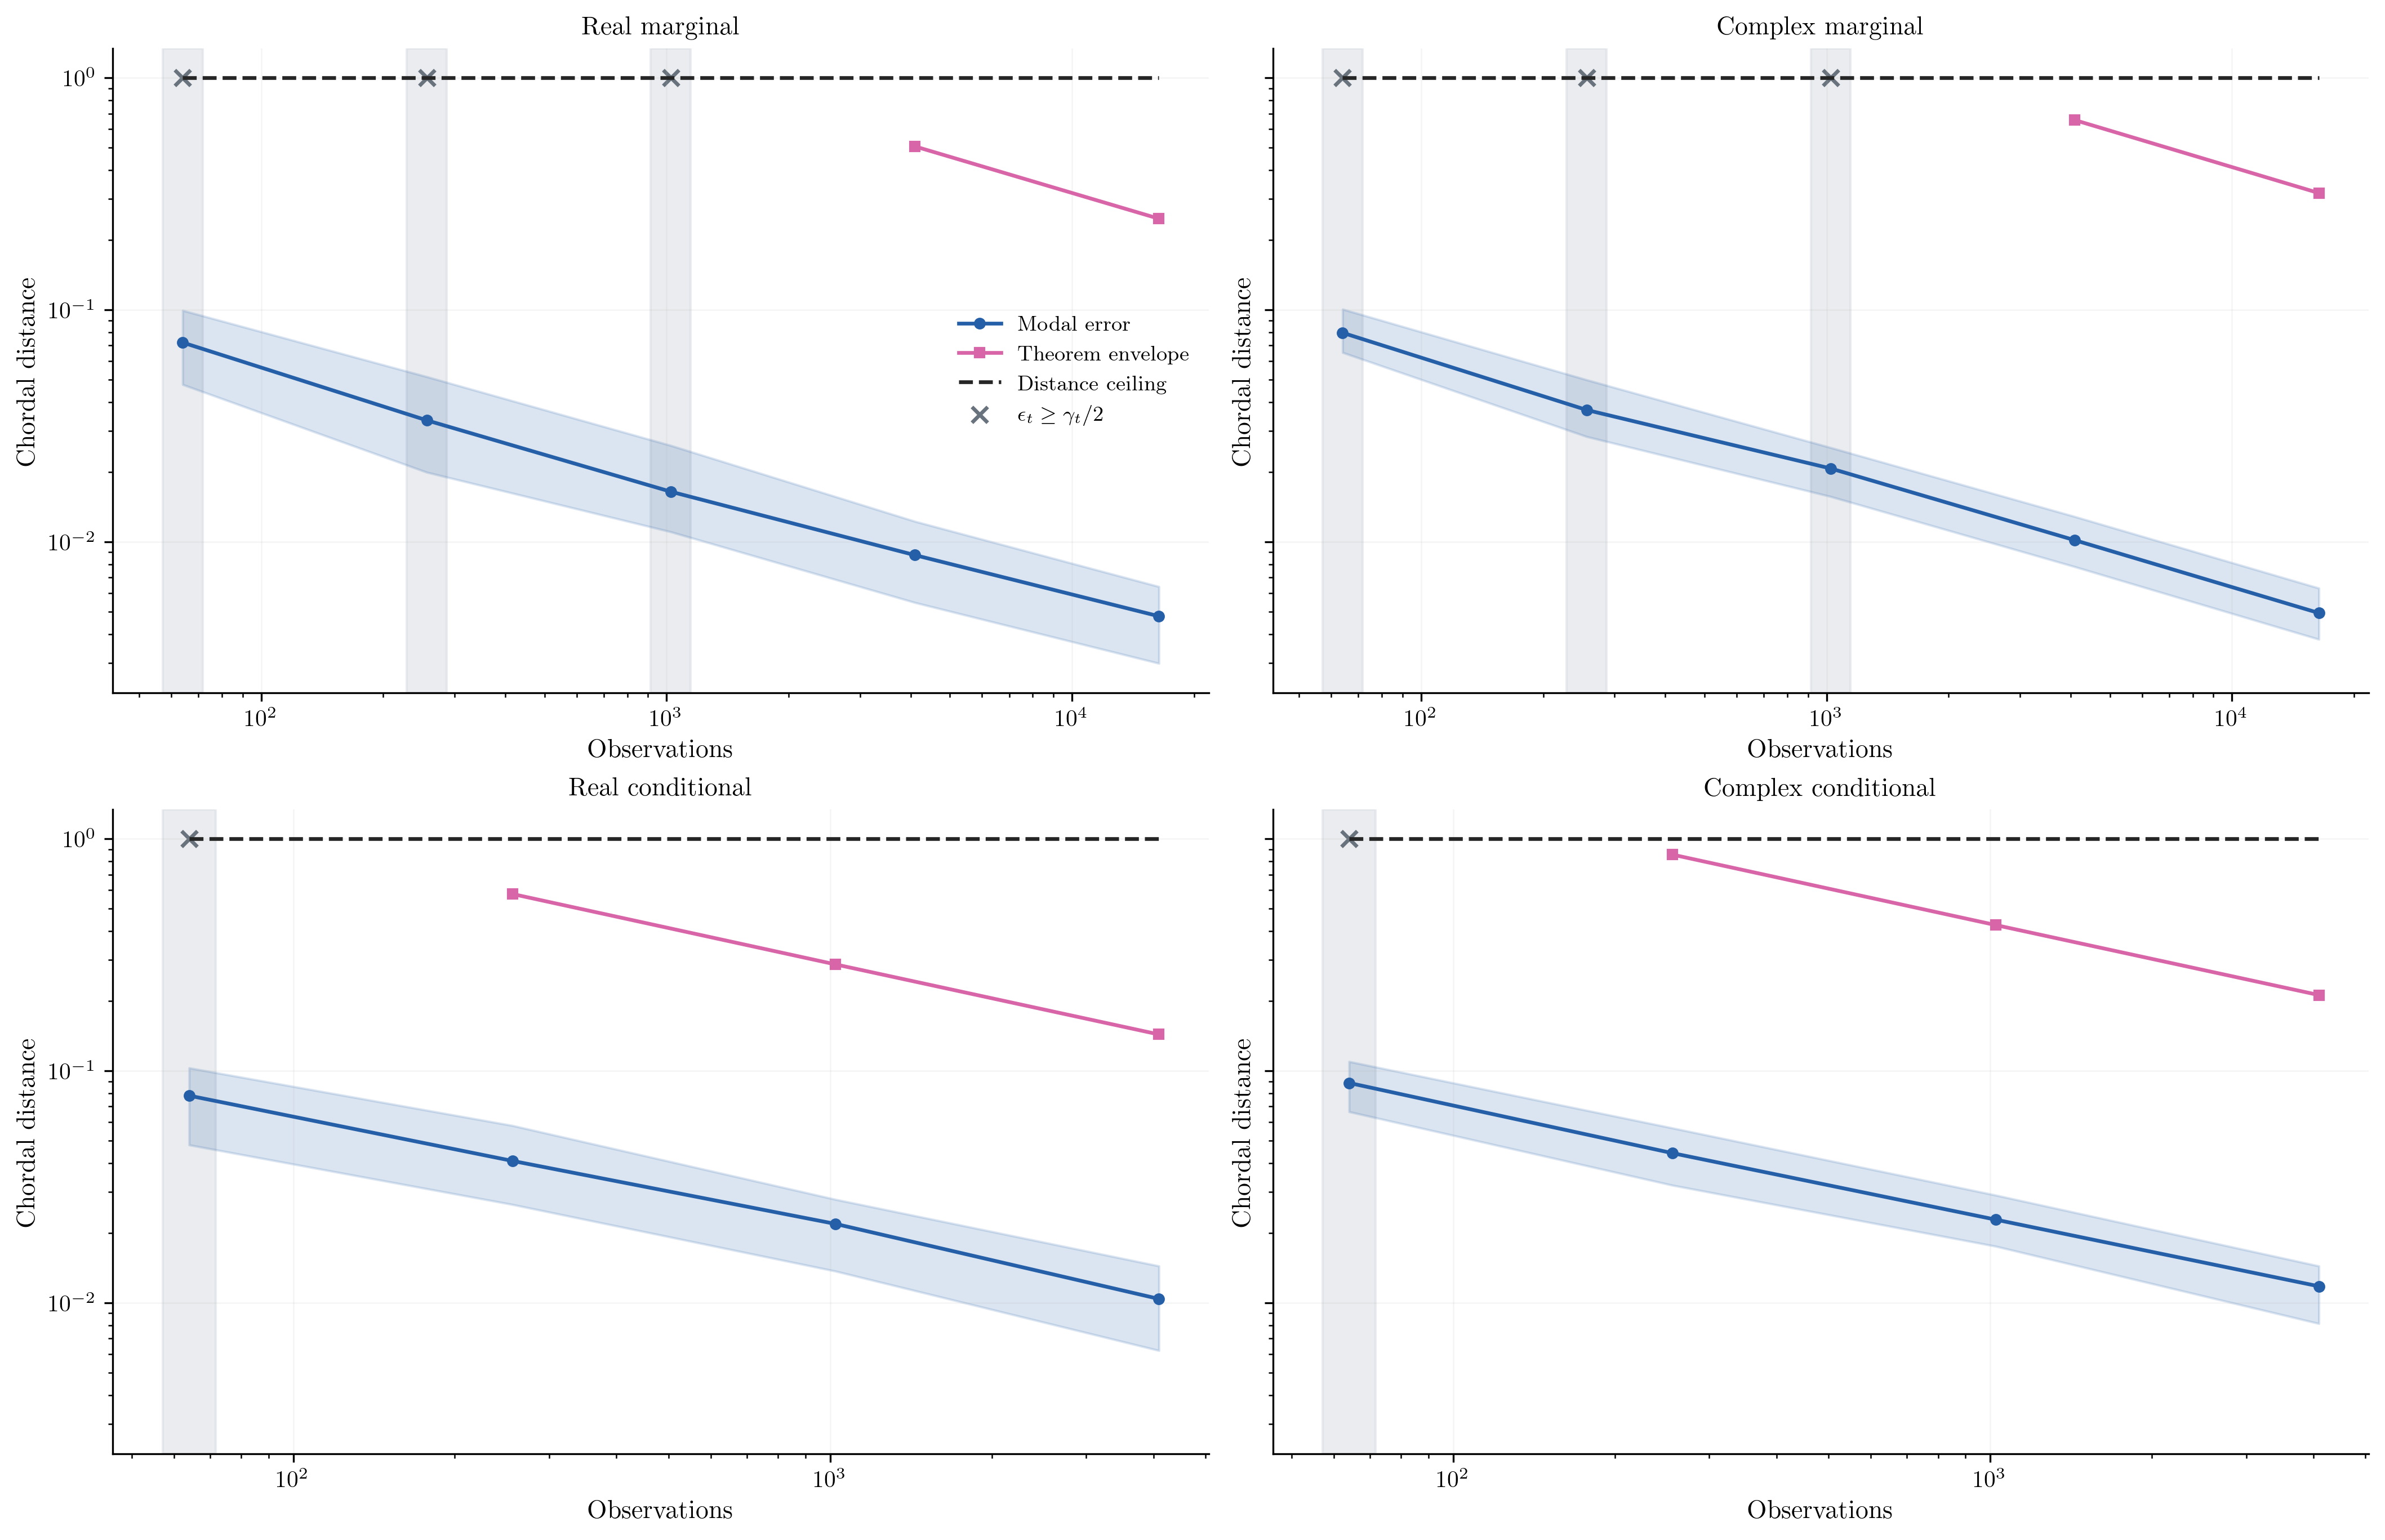

In [6]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (14, 9)
data = load_audit_data(ROOT, 'tracking')

frame = data['bounds']
types = [t for t in ['marginal_real', 'marginal_complex', 'conditional_real', 'conditional_complex'] if t in set(frame.observation_type)]
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE, layout='constrained', sharey=True, dpi=DPI)
for ax, kind in zip(axes.ravel(), types):
    g = frame[frame.observation_type.eq(kind) & frame.condition.eq('static')]
    g = g[np.isclose(g.beta, 1.0)]
    if g.empty:
        raise RuntimeError('Missing declared static beta=1 reference for ' + kind)
    g = g[g.n.eq(g.n.min())]
    fixed = g[['s', 'tau2']].drop_duplicates().iloc[0]
    g = g[np.isclose(g.s, fixed.s) & (g.tau2.isna() | np.isclose(g.tau2, fixed.tau2, equal_nan=True))]
    summary = g.groupby('t').agg(error=('modal_error', 'median'), lower=('modal_error', lambda x: x.quantile(0.25)), upper=('modal_error', lambda x: x.quantile(0.75)), bound=('bound', 'median'), valid=('valid', 'mean'), ceiling=('ceiling', 'first'))
    ax.plot(summary.index, summary.error, 'o-', color=BLUE, label='Modal error')
    ax.fill_between(summary.index, summary.lower, summary.upper, color=BLUE, alpha=0.16)
    ax.plot(summary.index, summary.bound, 's-', color=PINK, label='Theorem envelope')
    ax.plot(summary.index, summary.ceiling, '--', color=BLACK, label='Distance ceiling')
    failed = summary[summary.valid.lt(1)]
    for time in failed.index:
        ax.axvspan(time / 1.12, time * 1.12, color='#D9DDE2', alpha=0.55, zorder=0)
    ax.scatter(failed.index, failed.ceiling, marker='x', color=GREY, s=45, label='$\\epsilon_t\\ge\\gamma_t/2$')
    ax.set(xscale='log', yscale='log', xlabel='Observations', ylabel='Chordal distance', title=CHANNELS.get(kind, text_label(kind)))
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='both', alpha=0.13, linewidth=0.6)
for ax in axes.ravel()[len(types):]:
    ax.set_visible(False)
axes.ravel()[0].legend(frameon=False, fontsize=9)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'B3_C4_modal_bounds.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## B3; C4. More time does not always fix a memory-limited bound

At $\beta<1$, the guide's stationary ratio has a positive limit:
$4(1+s/\tau^2)[\sqrt{h(1-\beta)/(1+\beta)}+h(1-\beta)]$.
If this limit is too large, increasing the horizon alone cannot make the sufficient condition informative. The phase diagram varies the declared drift and memory independently. Fixed-time violation counts, eligible episode counts and binomial intervals are kept separately; zero observed violations is not proof of a uniform-in-time guarantee.

In [7]:
from lib.guide_tracking import marginal_preflight
for beta in [1.0, 0.99]:
    check = marginal_preflight(n=3, s=0.2, tau2=1.0, t=16384, beta=beta)
    print('beta =', beta, ': epsilon/gamma =', round(check['ratio'], 3),
          '; gap condition =', check['valid'],
          '; permanently vacuous =', check['permanently_vacuous'])

beta = 1.0 : epsilon/gamma = 0.123 ; gap condition = True ; permanently vacuous = False
beta = 0.99 : epsilon/gamma = 1.584 ; gap condition = False ; permanently vacuous = True


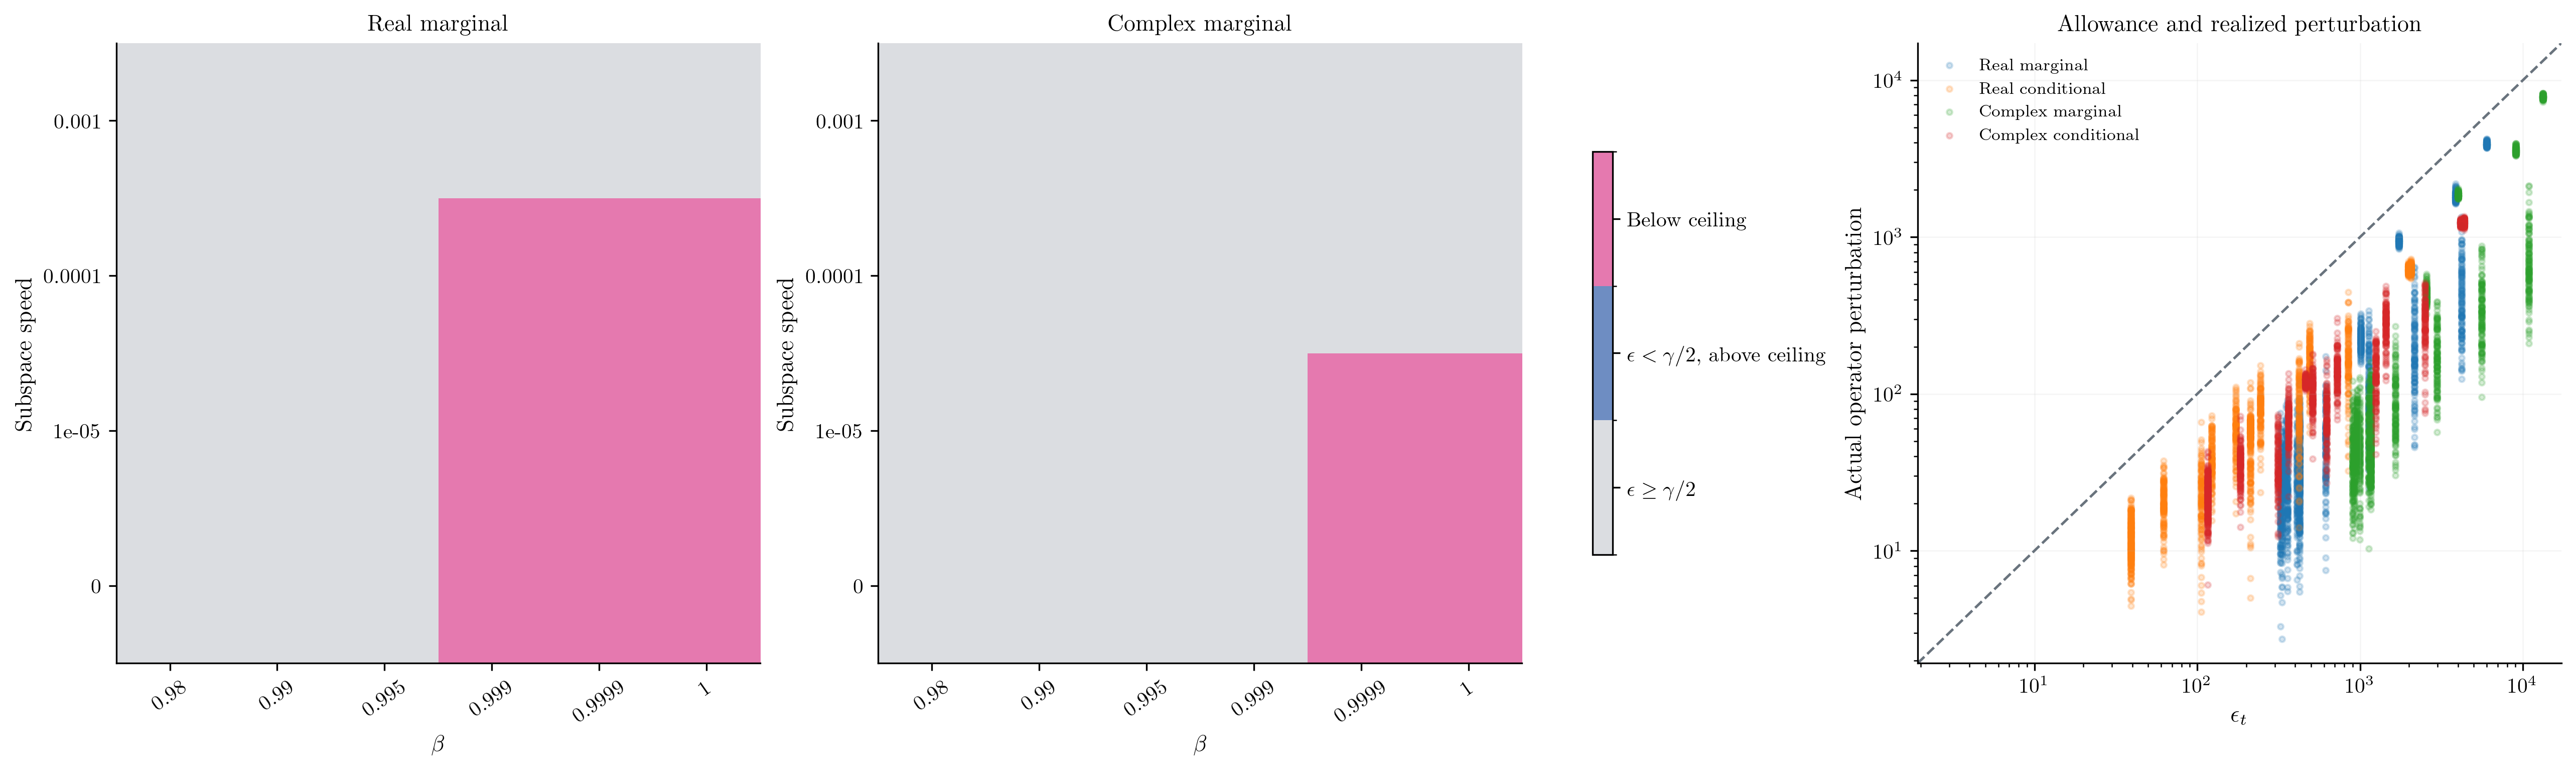

In [8]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (17, 5)
data = load_audit_data(ROOT, 'tracking')

frame = data['phase']
types = list(frame.observation_type.drop_duplicates())
fig, axes = plt.subplots(1, len(types) + 1, figsize=FIGSIZE, layout='constrained', squeeze=False, dpi=DPI)
cmap = ListedColormap(['#DBDDE1', '#6E8DC2', '#E579AF'])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3)
for ax, kind in zip(axes.ravel(), types):
    g = frame[frame.observation_type.eq(kind)]
    g = g[g.t.eq(g.t.max()) & g.n.eq(g.n.min())].copy()
    g['display'] = np.where(g.informative, 2, np.where(g.valid, 1, 0))
    matrix = g.pivot_table(index='drift_rate', columns='beta', values='display', aggfunc='min')
    im = ax.imshow(matrix, origin='lower', aspect='auto', cmap=cmap, norm=norm)
    ax.set(xticks=np.arange(len(matrix.columns)), xticklabels=[f'{v:g}' for v in matrix.columns], yticks=np.arange(len(matrix.index)), yticklabels=[f'{v:g}' for v in matrix.index], xlabel='$\\beta$', ylabel='Subspace speed', title=CHANNELS.get(kind, text_label(kind)))
    ax.tick_params(axis='x', labelrotation=35)
colorbar = fig.colorbar(im, ax=list(axes.ravel()[:-1]), ticks=[0, 1, 2], shrink=0.65)
colorbar.ax.set_yticklabels(['$\\epsilon\\ge\\gamma/2$', '$\\epsilon<\\gamma/2$, above ceiling', 'Below ceiling'])
actual = data['bounds']
ax = axes.ravel()[-1]
for kind, group in actual.groupby('observation_type', sort=False):
    ax.scatter(group.epsilon, group.actual_perturbation, s=7, alpha=0.2, label=CHANNELS.get(kind, text_label(kind)))
x = actual.epsilon.to_numpy()
y = actual.actual_perturbation.to_numpy()
positive = np.r_[x, y]
positive = positive[np.isfinite(positive) & (positive > 0)]
lo, hi = (float(positive.min() * 0.7), float(positive.max() * 1.3))
ax.plot([lo, hi], [lo, hi], '--', color=GREY, lw=1.2)
ax.set(xlim=(lo, hi), ylim=(lo, hi), xscale='log', yscale='log', xlabel='$\\epsilon_t$', ylabel='Actual operator perturbation', title='Allowance and realized perturbation')
ax.legend(frameon=False, fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='both', alpha=0.13, linewidth=0.6)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'B3_C4_validity.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## B5. Compare decisions on fresh measurements

The posterior-mean covariance minimizes posterior expected output power under unit desired gain. It does not maximize expected SINR. The paired held-out measurements below are independent of training and shared by the competing decisions. A dot is one independent training episode, after averaging its held-out observations.

The matched-isotropy control and validation-loaded covariance remain in the full comparison tables. Matching modal overlap preserves trace and expected squared chordal loss, but does not preserve directional information. Matching a covariance alone also does not specify a predictive probability law.

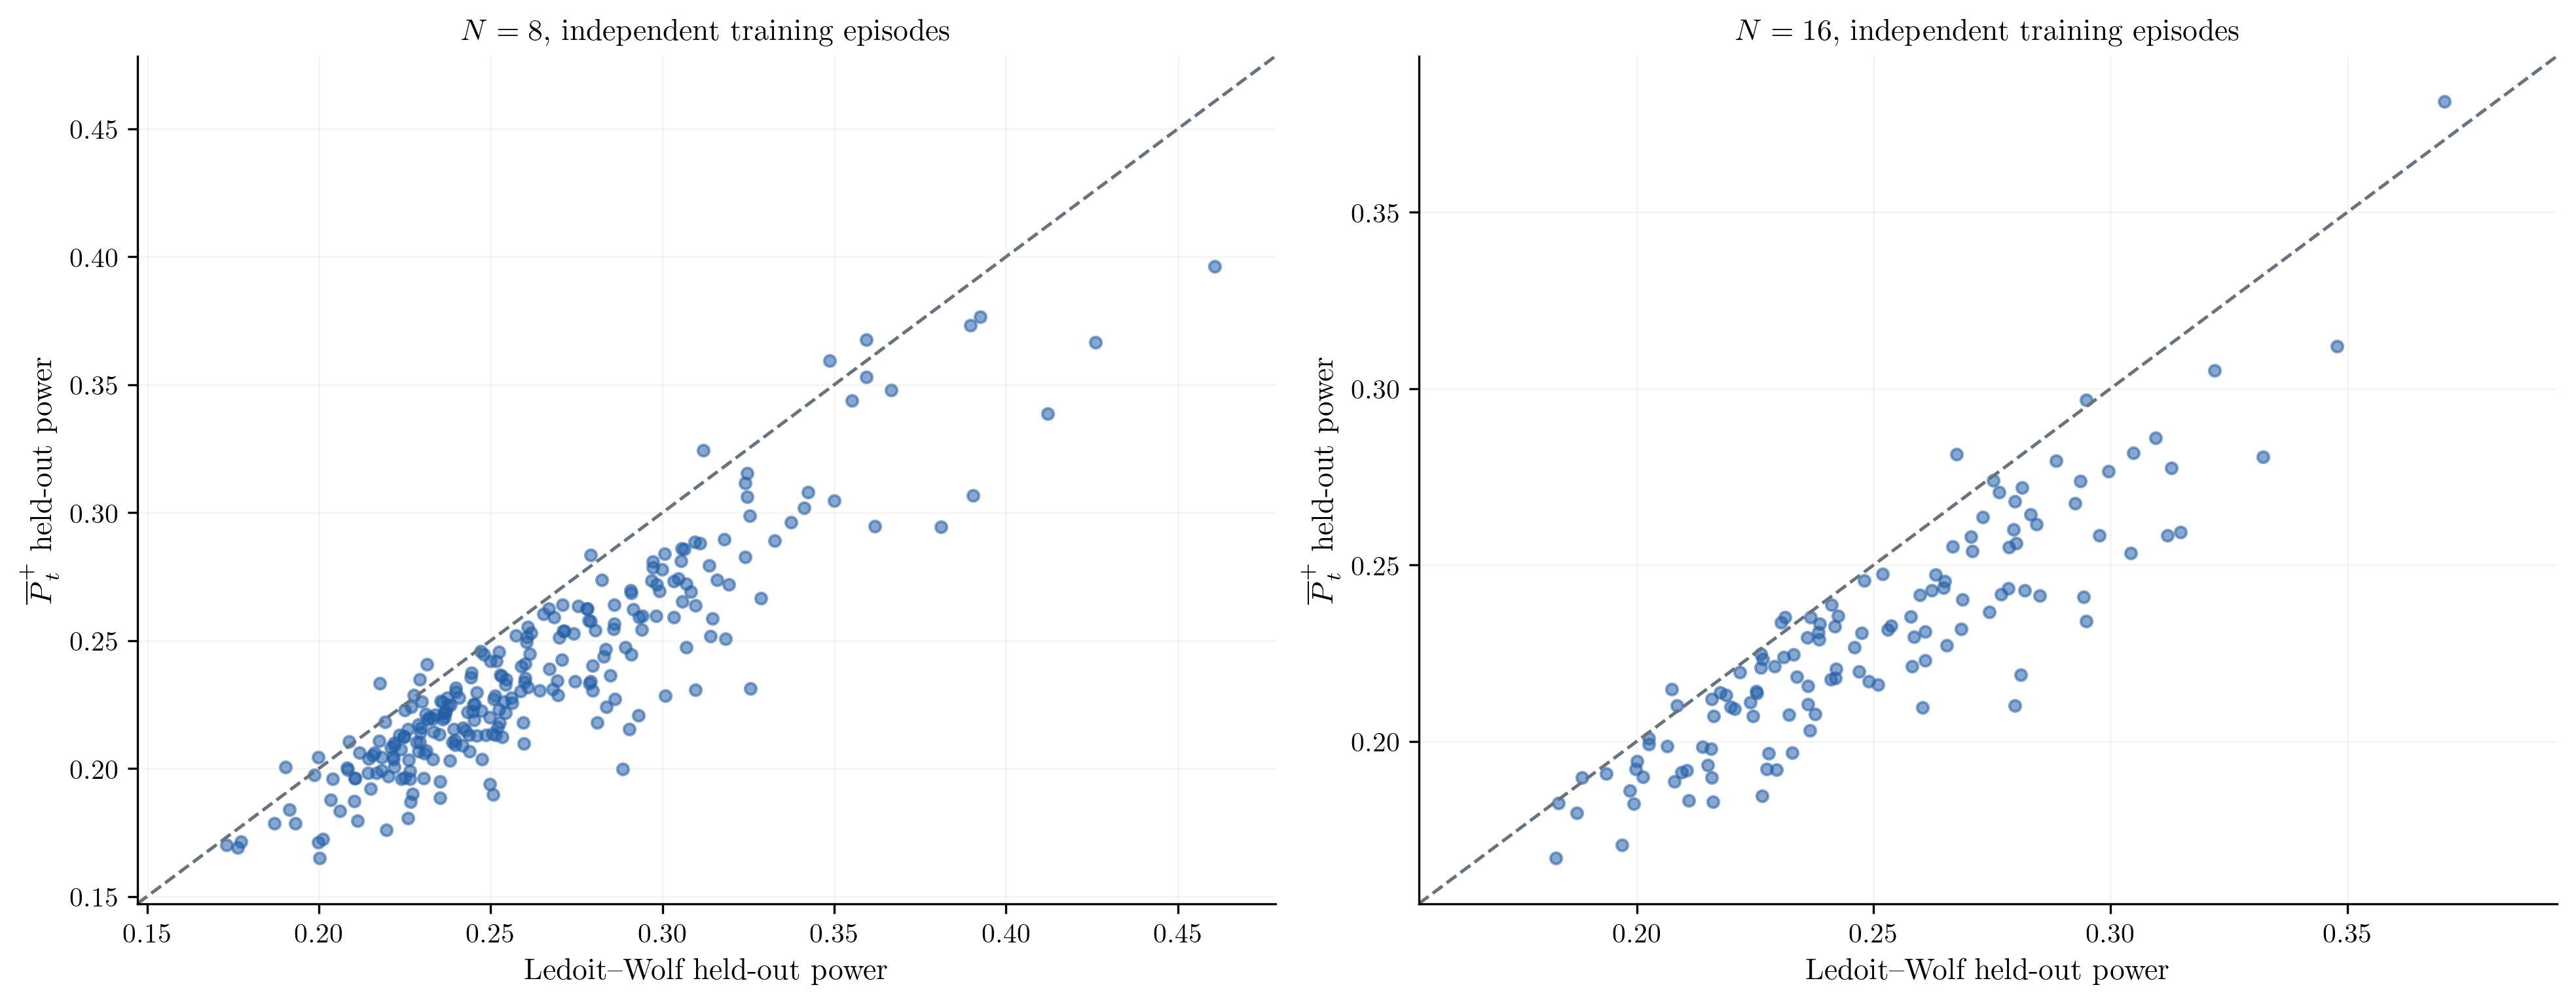

In [9]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (13, 5)
main = load_audit_data(ROOT, 'heldout')

metrics = main['beamforming']['metrics']
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, layout='constrained', dpi=DPI)
for ax, n in zip(axes, [8, 16]):
    f = metrics[metrics.n.eq(n) & metrics.law.eq('haar') & metrics.t.eq(16) & np.isclose(metrics.s, 0.2)]
    g = f.pivot(index='trial', columns='method', values='heldout_power')
    ax.scatter(g.lw, g['mean'], s=17, alpha=0.55, color=BLUE)
    _identity_values_1 = np.r_[np.asarray(g.lw, float), np.asarray(g['mean'], float)]
    _identity_values_1 = _identity_values_1[np.isfinite(_identity_values_1)]
    _identity_low_1, _identity_high_1 = (float(_identity_values_1.min()), float(_identity_values_1.max()))
    _identity_pad_1 = max((_identity_high_1 - _identity_low_1) * 0.06, abs(_identity_high_1) * 0.02, 1e-12)
    ax.plot([_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1], [_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1], '--', color=GREY, lw=1.2)
    ax.set(xlim=(_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1), ylim=(_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1))
    ax.set(xlabel='Ledoit--Wolf held-out power', ylabel='$\\overline P_t^+$ held-out power', title=f'$N={n}$, independent training episodes')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='both', alpha=0.13, linewidth=0.6)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'B5_heldout_decisions.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## B5. Keep changing motion, noise and power as separate interventions

The new tracking experiment uses snapshots alone and identity transport. It retains static, smoothly drifting and abruptly changing signatures, then changes sensor noise and interference power separately. The left panel compares a strong covariance decision with the posterior mean; the right holds the modal decision rule fixed while changing only its independently selected memory. A memory benefit is not an anisotropy benefit.

Every declared condition remains, including losses. Boxes contain independent paired episodes at the final prescribed checkpoint. The complete paired intervals and earlier checkpoints remain in the tables.

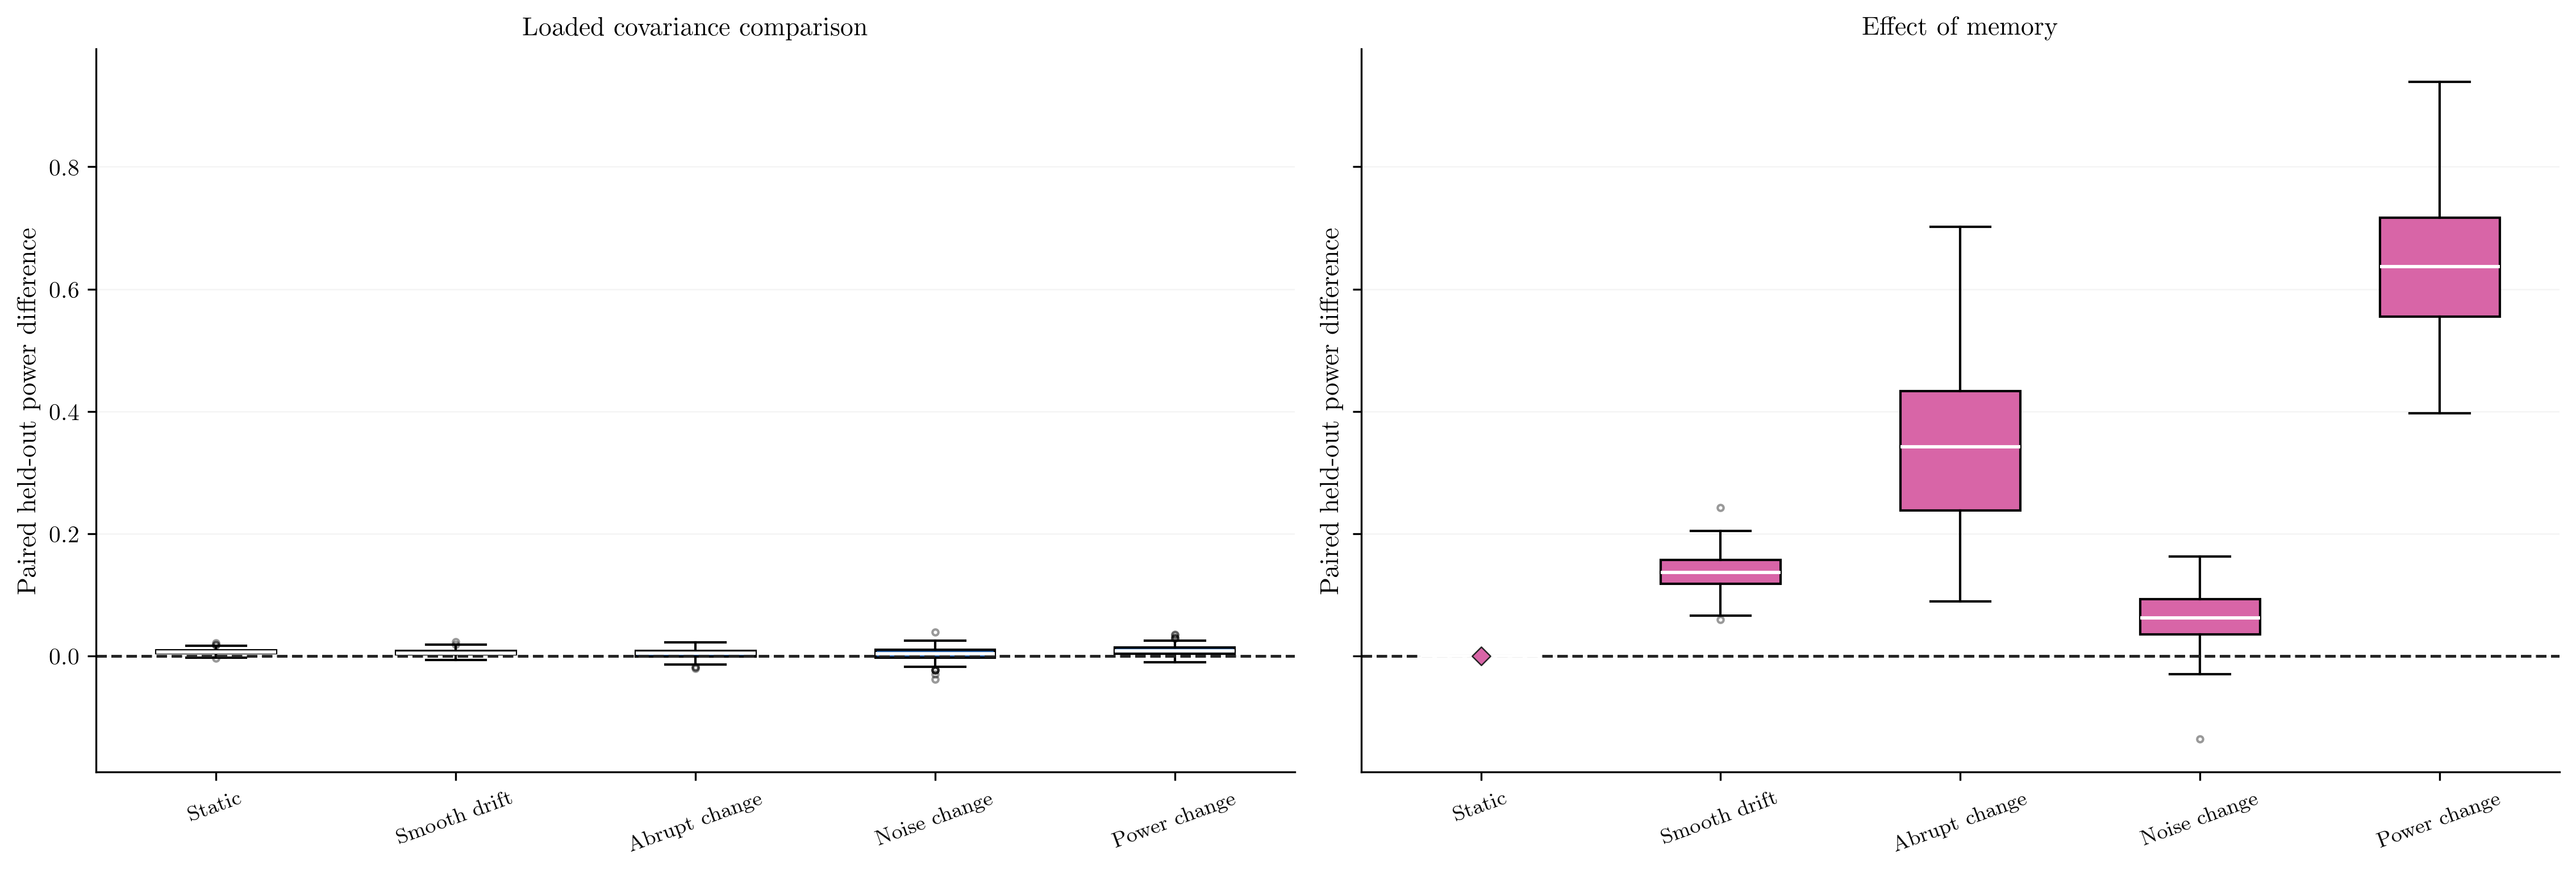

In [10]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (15, 5)
data = load_audit_data(ROOT, 'tracking')

frame = data['beamforming']
frame = frame[frame.t.eq(frame.t.max())]
names = [name for name in ['static', 'drift', 'abrupt', 'noise', 'power'] if name in set(frame.condition)]
labels = {'static': 'Static', 'drift': 'Smooth drift', 'abrupt': 'Abrupt change', 'noise': 'Noise change', 'power': 'Power change'}
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, layout='constrained', sharey=True, dpi=DPI)
for ax, reference, own, title, color in zip(axes, ['scm', 'mode_beta1'], ['mean', 'mode'], ['Loaded covariance comparison', 'Effect of memory'], [BLUE, PINK]):
    arrays = []
    for condition in names:
        rows = frame[frame.condition.eq(condition)]
        pair = rows.pivot(index='trial', columns='method', values='heldout_power')
        arrays.append((pair[reference] - pair[own]).to_numpy())
    artists = ax.boxplot(arrays, tick_labels=[labels[name] for name in names], patch_artist=True, medianprops={'color': 'white', 'linewidth': 1.4}, flierprops={'markersize': 2.5, 'alpha': 0.4})
    for box in artists['boxes']:
        box.set_facecolor(color)
    for position, values in enumerate(arrays, 1):
        if len(values) and np.ptp(values) == 0:
            ax.scatter(position, values[0], marker='D', s=30, color=color, edgecolors=BLACK, lw=0.6, zorder=5)
    ax.axhline(0, color=BLACK, ls='--', lw=1.2)
    ax.set(ylabel='Paired held-out power difference', title=title)
    ax.tick_params(axis='x', labelrotation=20, labelsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.13, linewidth=0.6)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'B5_tracking_decisions.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## B6. State coverage, response risk and predictive density

Prior-predictive calibration first draws the state from the stated prior and then draws its data. Fixed-state and drifting-state repeated-data inclusion answer different questions. State regions, clean-response intervals and noisy predictive intervals are recorded separately, with episode-level uncertainty.

Scores are evaluated before assimilation from the full normalized singleton likelihood and the normalizer ratio. A Gaussian with covariance $sI+\tau^2\overline P$ matches a predictive second moment; it is a separate density from the projector mixture. Neither numerical accuracy of the mean nor a credible-mass identity guarantees fixed-state scalar coverage.

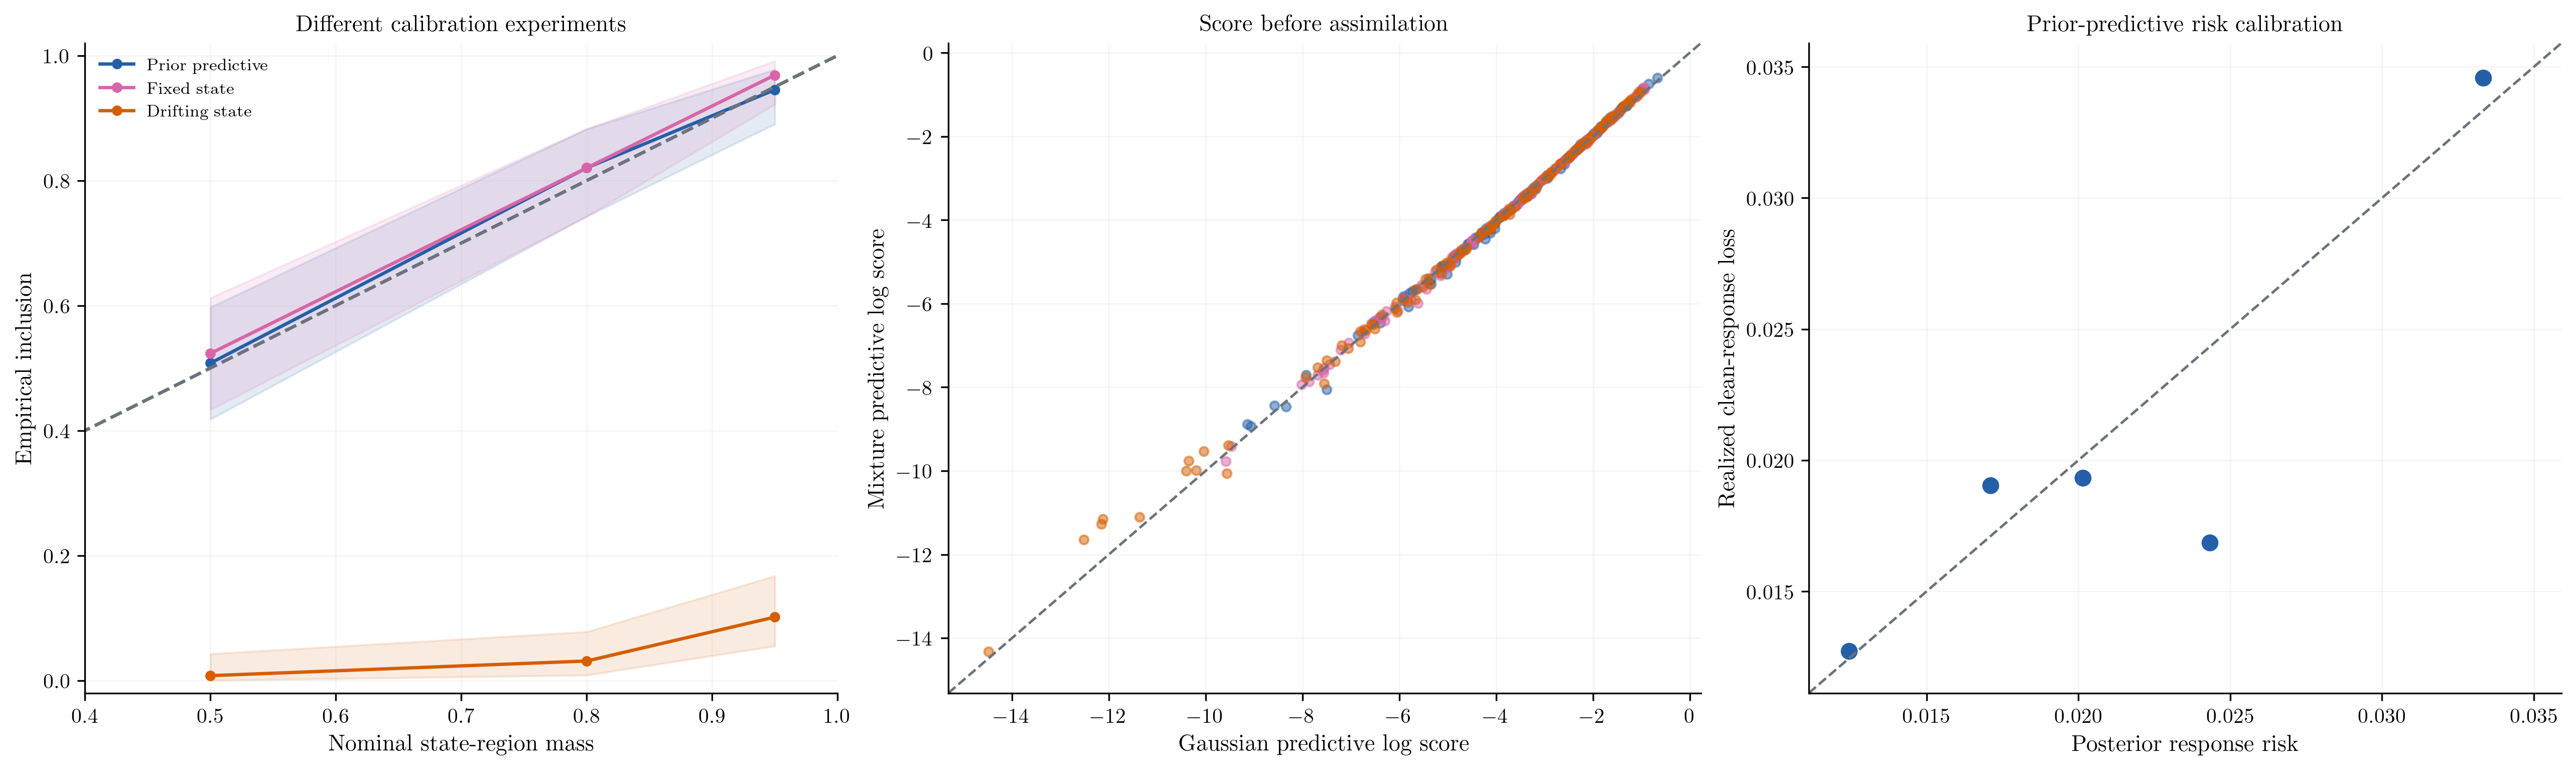

In [11]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (17, 5)
data = load_audit_data(ROOT, 'reliability')
model = 'beamforming'

raw, scores = (data['calibration'], data['scores'])
raw = raw[raw.model.eq(model)]
if 'stage' in raw:
    raw = raw[raw.stage.eq('test')]
scores = scores[scores.model.eq(model)]
if 'stage' in scores:
    scores = scores[scores.stage.eq('test')]
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, layout='constrained', dpi=DPI)
coverage = data['calibration_summary']
coverage = coverage[coverage.model.eq(model) & coverage.stage.eq('test') & coverage.kind.eq('state_ball') & coverage.method.eq('posterior')]
for color, (regime, group) in zip((BLUE, PINK, ORANGE), coverage.groupby('regime', sort=False)):
    group = group.sort_values('nominal')
    axes[0].plot(group.nominal, group.coverage, 'o-', color=color, label=text_label(regime))
    axes[0].fill_between(group.nominal, group.lower, group.upper, color=color, alpha=0.12)
axes[0].plot([0, 1], [0, 1], '--', color=GREY)
axes[0].set(xlabel='Nominal state-region mass', ylabel='Empirical inclusion', xlim=(0.4, 1), ylim=(-0.02, 1.02), title='Different calibration experiments')
axes[0].legend(frameon=False, fontsize=8)
all_x, all_y = ([], [])
for color, (regime, group) in zip((BLUE, PINK, ORANGE), scores.groupby('regime', sort=False)):
    episode = group.groupby('episode')[['mixture_log_score', 'gaussian_log_score']].mean()
    axes[1].scatter(episode.gaussian_log_score, episode.mixture_log_score, s=18, alpha=0.5, color=color, label=text_label(regime))
    all_x.extend(episode.gaussian_log_score)
    all_y.extend(episode.mixture_log_score)
_identity_values_1 = np.r_[np.asarray(all_x, float), np.asarray(all_y, float)]
_identity_values_1 = _identity_values_1[np.isfinite(_identity_values_1)]
_identity_low_1, _identity_high_1 = (float(_identity_values_1.min()), float(_identity_values_1.max()))
_identity_pad_1 = max((_identity_high_1 - _identity_low_1) * 0.06, abs(_identity_high_1) * 0.02, 1e-12)
axes[1].plot([_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1], [_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1], '--', color=GREY, lw=1.2)
axes[1].set(xlim=(_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1), ylim=(_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1))
axes[1].set(xlabel='Gaussian predictive log score', ylabel='Mixture predictive log score', title='Score before assimilation')
prior = scores[scores.regime.eq('prior_predictive')]
if prior.empty:
    raise RuntimeError('Missing prior-predictive risk reference')
episode = prior.groupby('episode')[['risk_predicted', 'risk_realized']].mean()
episode['bin'] = pd.qcut(episode.risk_predicted, q=min(5, len(episode)), labels=False, duplicates='drop')
points = episode.groupby('bin')[['risk_predicted', 'risk_realized']].mean()
axes[2].scatter(points.risk_predicted, points.risk_realized, color=BLUE, s=50)
_identity_values_2 = np.r_[np.asarray(points.risk_predicted, float), np.asarray(points.risk_realized, float)]
_identity_values_2 = _identity_values_2[np.isfinite(_identity_values_2)]
_identity_low_2, _identity_high_2 = (float(_identity_values_2.min()), float(_identity_values_2.max()))
_identity_pad_2 = max((_identity_high_2 - _identity_low_2) * 0.06, abs(_identity_high_2) * 0.02, 1e-12)
axes[2].plot([_identity_low_2 - _identity_pad_2, _identity_high_2 + _identity_pad_2], [_identity_low_2 - _identity_pad_2, _identity_high_2 + _identity_pad_2], '--', color=GREY, lw=1.2)
axes[2].set(xlim=(_identity_low_2 - _identity_pad_2, _identity_high_2 + _identity_pad_2), ylim=(_identity_low_2 - _identity_pad_2, _identity_high_2 + _identity_pad_2))
axes[2].set(xlabel='Posterior response risk', ylabel='Realized clean-response loss', title='Prior-predictive risk calibration')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='both', alpha=0.13, linewidth=0.6)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'B6_beam_calibration.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## C5. Apply the same probability distinctions to contact

The conditional model uses observed requests and directly measured instantaneous velocities with independent Gaussian sensor noise. Clean contact-response risk is evaluated on a fresh request. The calibration displays use the same conventions as beamforming, so observed differences can be traced to the observation model rather than a changed definition of coverage.

Every repeated-time quantity is averaged within an episode before comparing independent episodes. Validation-selected width adjustments and their independent test coverage remain in the tables; adjusting a width on test truth would invalidate that comparison.

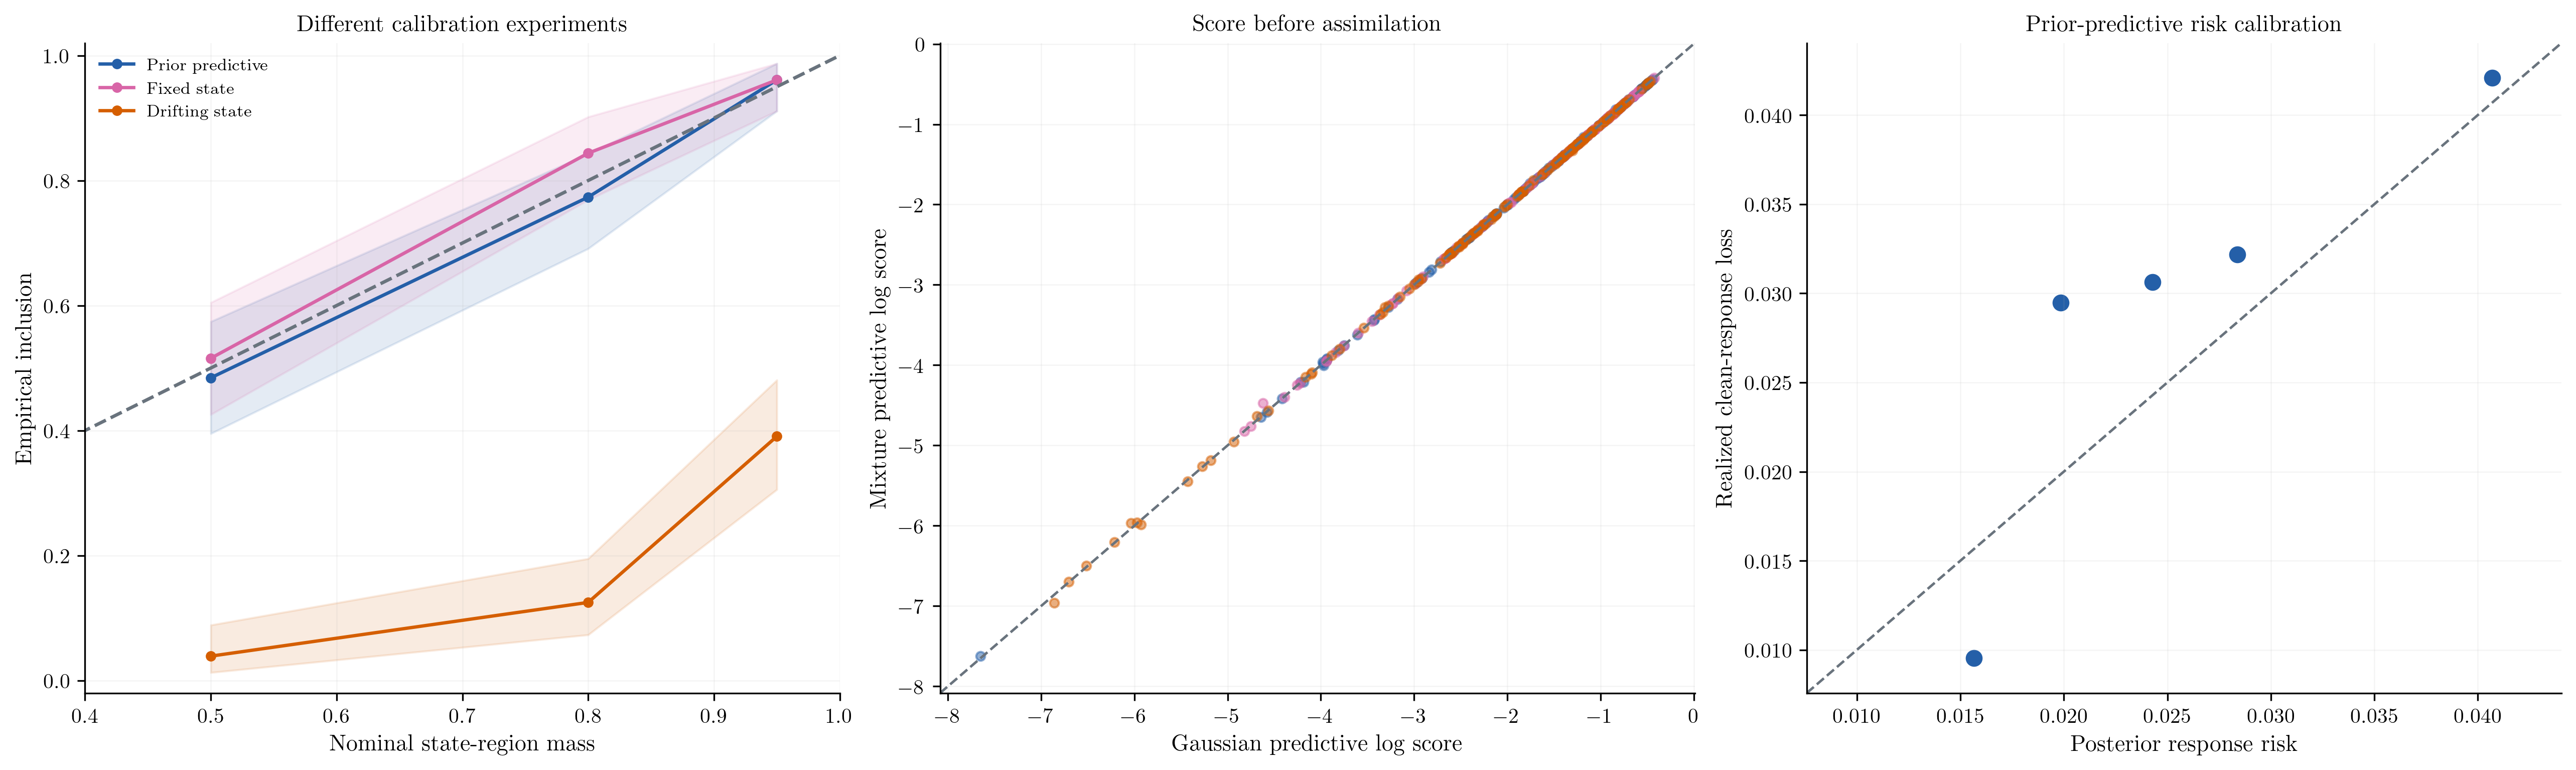

In [12]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (17, 5)
data = load_audit_data(ROOT, 'reliability')
model = 'contact'

raw, scores = (data['calibration'], data['scores'])
raw = raw[raw.model.eq(model)]
if 'stage' in raw:
    raw = raw[raw.stage.eq('test')]
scores = scores[scores.model.eq(model)]
if 'stage' in scores:
    scores = scores[scores.stage.eq('test')]
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, layout='constrained', dpi=DPI)
coverage = data['calibration_summary']
coverage = coverage[coverage.model.eq(model) & coverage.stage.eq('test') & coverage.kind.eq('state_ball') & coverage.method.eq('posterior')]
for color, (regime, group) in zip((BLUE, PINK, ORANGE), coverage.groupby('regime', sort=False)):
    group = group.sort_values('nominal')
    axes[0].plot(group.nominal, group.coverage, 'o-', color=color, label=text_label(regime))
    axes[0].fill_between(group.nominal, group.lower, group.upper, color=color, alpha=0.12)
axes[0].plot([0, 1], [0, 1], '--', color=GREY)
axes[0].set(xlabel='Nominal state-region mass', ylabel='Empirical inclusion', xlim=(0.4, 1), ylim=(-0.02, 1.02), title='Different calibration experiments')
axes[0].legend(frameon=False, fontsize=8)
all_x, all_y = ([], [])
for color, (regime, group) in zip((BLUE, PINK, ORANGE), scores.groupby('regime', sort=False)):
    episode = group.groupby('episode')[['mixture_log_score', 'gaussian_log_score']].mean()
    axes[1].scatter(episode.gaussian_log_score, episode.mixture_log_score, s=18, alpha=0.5, color=color, label=text_label(regime))
    all_x.extend(episode.gaussian_log_score)
    all_y.extend(episode.mixture_log_score)
_identity_values_1 = np.r_[np.asarray(all_x, float), np.asarray(all_y, float)]
_identity_values_1 = _identity_values_1[np.isfinite(_identity_values_1)]
_identity_low_1, _identity_high_1 = (float(_identity_values_1.min()), float(_identity_values_1.max()))
_identity_pad_1 = max((_identity_high_1 - _identity_low_1) * 0.06, abs(_identity_high_1) * 0.02, 1e-12)
axes[1].plot([_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1], [_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1], '--', color=GREY, lw=1.2)
axes[1].set(xlim=(_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1), ylim=(_identity_low_1 - _identity_pad_1, _identity_high_1 + _identity_pad_1))
axes[1].set(xlabel='Gaussian predictive log score', ylabel='Mixture predictive log score', title='Score before assimilation')
prior = scores[scores.regime.eq('prior_predictive')]
if prior.empty:
    raise RuntimeError('Missing prior-predictive risk reference')
episode = prior.groupby('episode')[['risk_predicted', 'risk_realized']].mean()
episode['bin'] = pd.qcut(episode.risk_predicted, q=min(5, len(episode)), labels=False, duplicates='drop')
points = episode.groupby('bin')[['risk_predicted', 'risk_realized']].mean()
axes[2].scatter(points.risk_predicted, points.risk_realized, color=BLUE, s=50)
_identity_values_2 = np.r_[np.asarray(points.risk_predicted, float), np.asarray(points.risk_realized, float)]
_identity_values_2 = _identity_values_2[np.isfinite(_identity_values_2)]
_identity_low_2, _identity_high_2 = (float(_identity_values_2.min()), float(_identity_values_2.max()))
_identity_pad_2 = max((_identity_high_2 - _identity_low_2) * 0.06, abs(_identity_high_2) * 0.02, 1e-12)
axes[2].plot([_identity_low_2 - _identity_pad_2, _identity_high_2 + _identity_pad_2], [_identity_low_2 - _identity_pad_2, _identity_high_2 + _identity_pad_2], '--', color=GREY, lw=1.2)
axes[2].set(xlim=(_identity_low_2 - _identity_pad_2, _identity_high_2 + _identity_pad_2), ylim=(_identity_low_2 - _identity_pad_2, _identity_high_2 + _identity_pad_2))
axes[2].set(xlabel='Posterior response risk', ylabel='Realized clean-response loss', title='Prior-predictive risk calibration')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='both', alpha=0.13, linewidth=0.6)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'C5_contact_calibration.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## B7a; C6a. Fit one stationary block under one boundary prior

The revised block EM objective assumes one constant subspace and a boundary prior excluding the entire block. Every E-step reconstructs $A_\partial+\sum_jB_j(\theta)$ from that same boundary. Full normalized evidence restores scalar likelihood terms and trace-gauge constants. This differs from the historical product under separately recorded single-observation priors.

Marginal updates respect ordered noise/signal variances. Conditional noise updates include posterior subspace uncertainty; replacing the projector by its mean inside a squared residual omits that term. Several positive interior starts are compared by normalized evidence. With a uniform prior, a zero signal-variance start can be absorbing and is kept as a declared boundary diagnostic.

Each displayed curve is shifted by its own initial evidence, so its final height does not rank starts. Start selection uses the absolute normalized evidence recorded in `fits.csv`.

The small block below illustrates the library API and trace gauge. It is a deterministic replay, separate from the independent Monte Carlo cohorts shown in the figure.

In [13]:
from lib.block_em import BlockData, block_posterior, fit_block_em
U = np.array([[1.0, 0.1, 0.0], [0.8, -0.1, 0.1], [1.1, 0.0, -0.1],
              [-0.9, 0.1, 0.1], [-1.2, -0.1, 0.0], [0.7, 0.0, 0.1]])
A_boundary = np.diag([0.3, -0.2, -0.1])
block = BlockData(U, k=1, boundary_prior=A_boundary)
shifted = BlockData(U, k=1, boundary_prior=A_boundary + 7 * np.eye(3))
post = block_posterior(block, s=0.2, tau2=1.0)
post_shifted = block_posterior(shifted, s=0.2, tau2=1.0)
assert np.allclose(post.mean, post_shifted.mean, atol=1e-9)
assert abs(post.log_evidence - post_shifted.log_evidence) < 1e-8
fit = fit_block_em(block, s=0.2, tau2=1.0, iterations=6)
assert np.min(np.diff(fit.objectives)) >= -1e-8
print('Gauge evidence error:', abs(post.log_evidence - post_shifted.log_evidence))
print('Accepted/rejected steps:', fit.accepted, '/', fit.rejected)
print('Block log-evidence increase:', fit.objectives[-1] - fit.objectives[0])

Gauge evidence error: 3.552713678800501e-15
Accepted/rejected steps: 6 / 0
Block log-evidence increase: 11.254307752970895


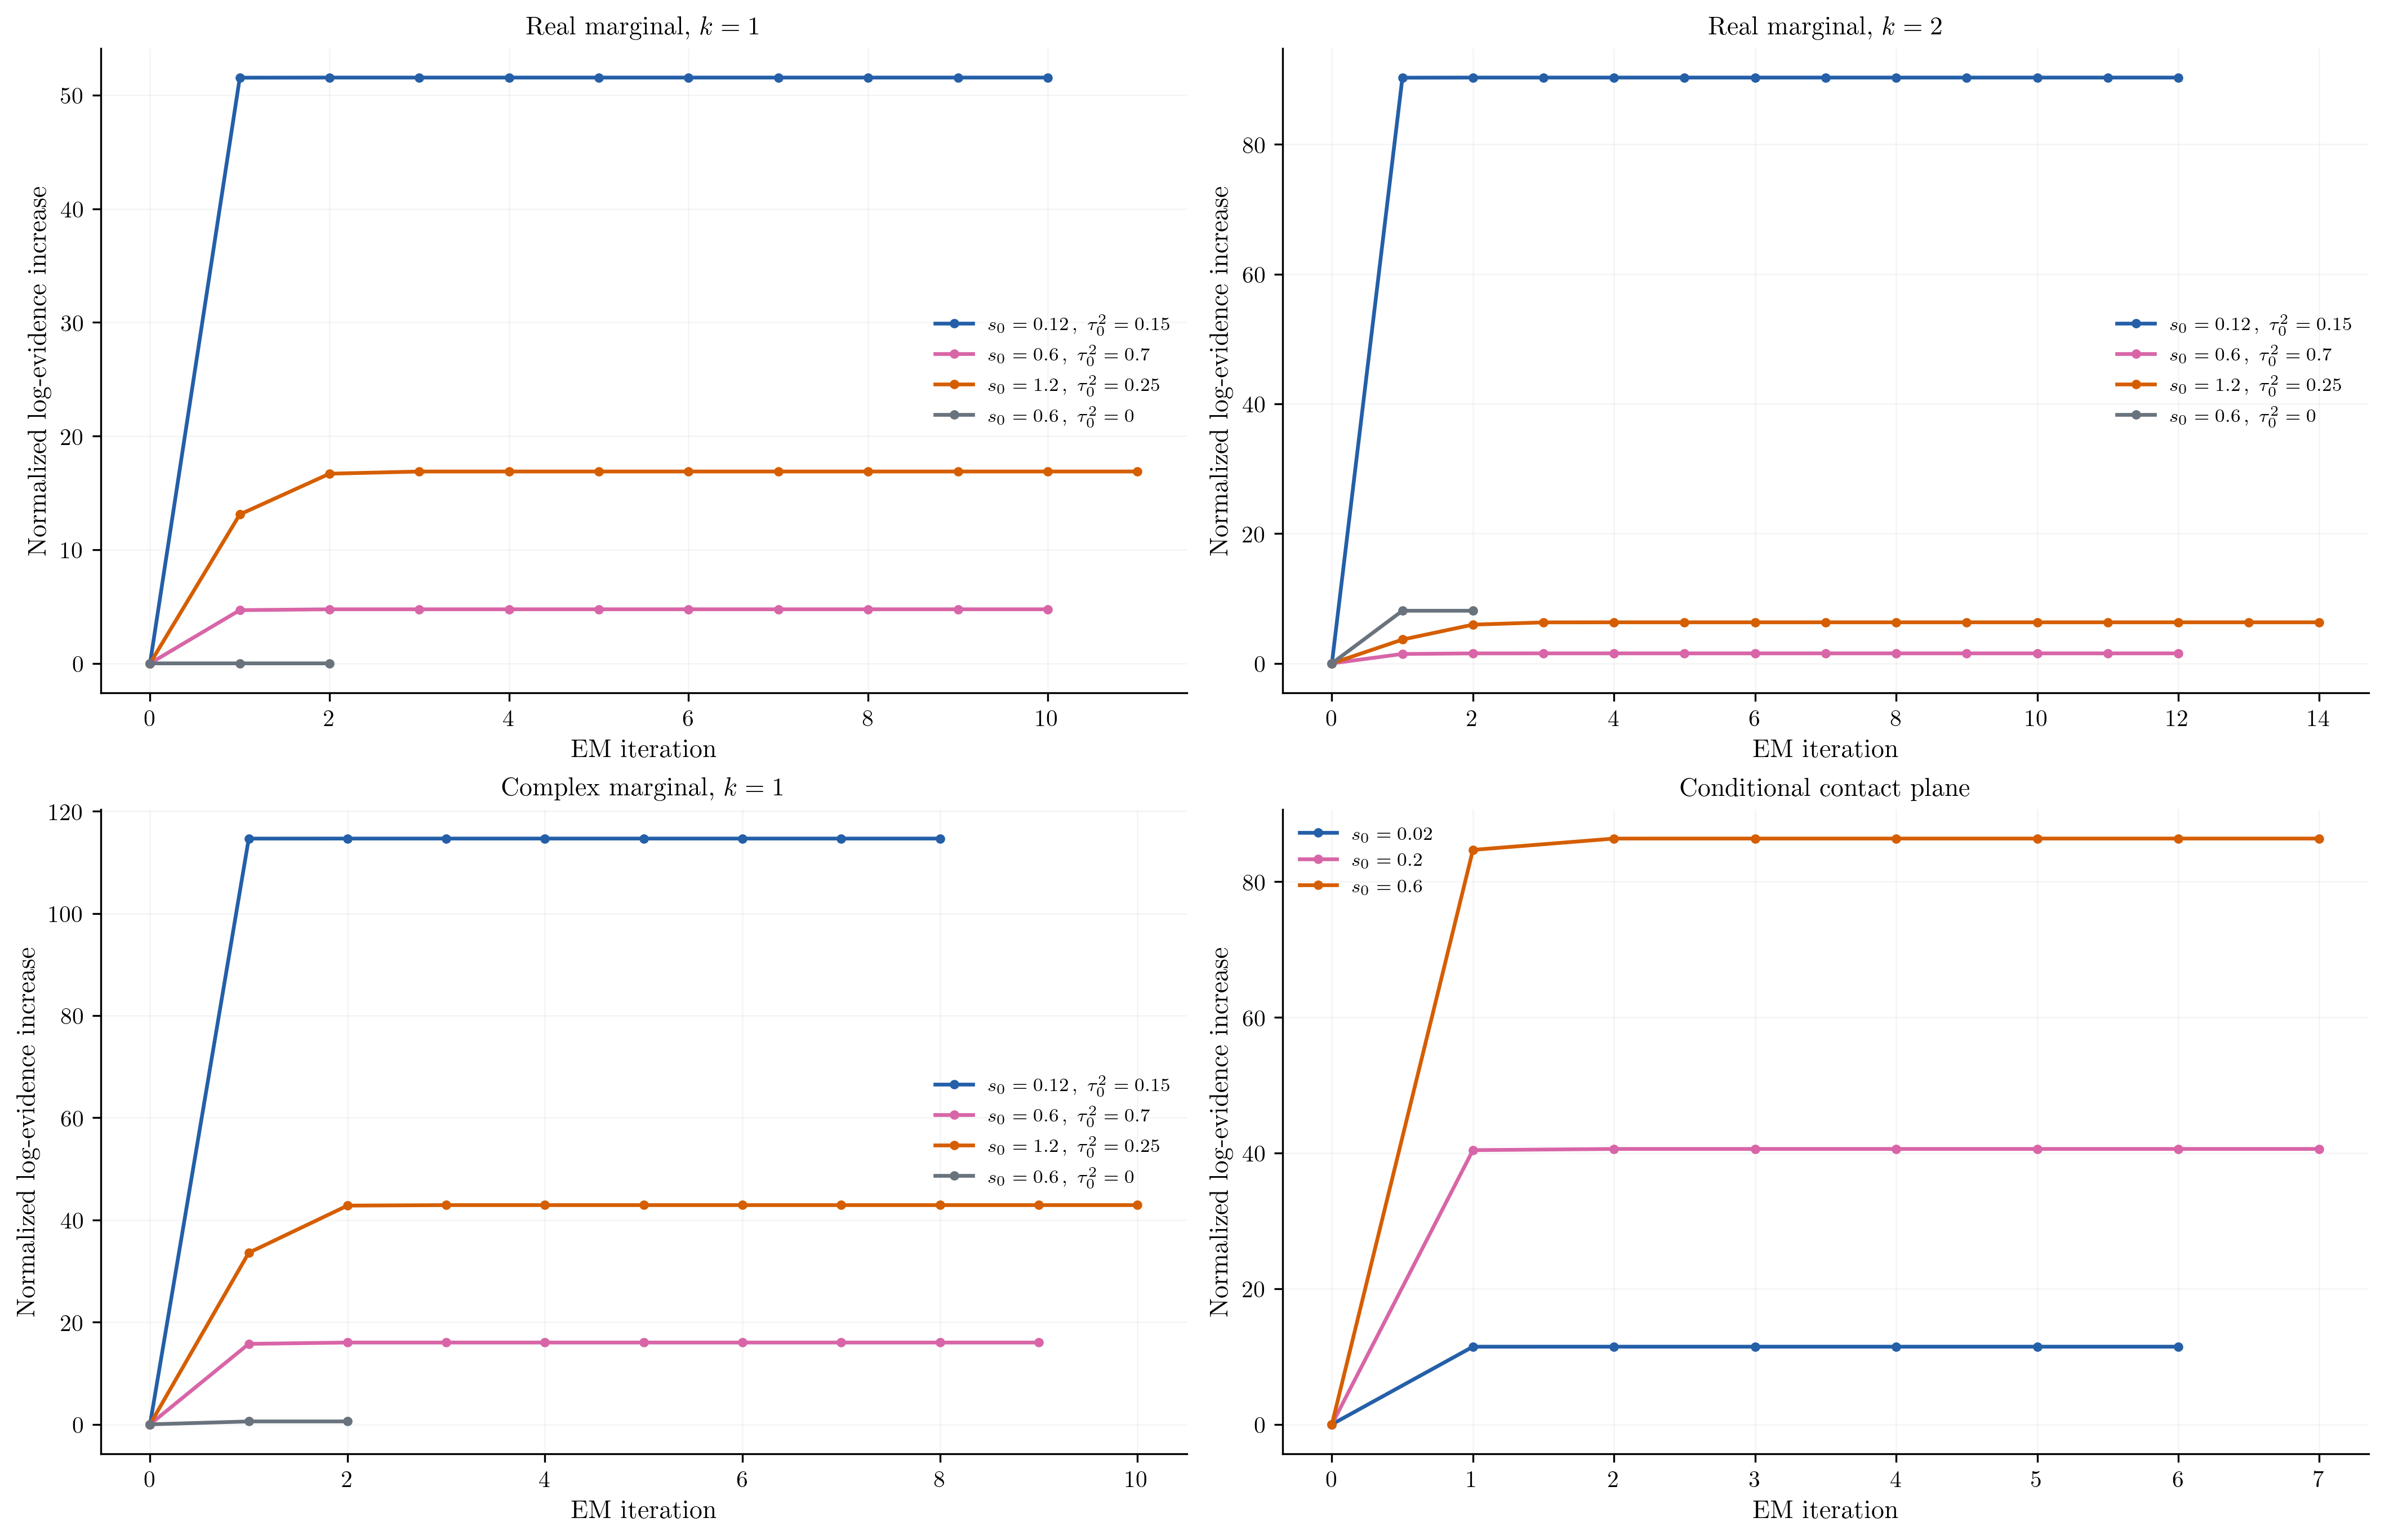

In [14]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (14, 9)
data = load_audit_data(ROOT, 'em')

frame = data['iterations']
models = list(frame.model.drop_duplicates())
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE, layout='constrained', squeeze=False, dpi=DPI)
for ax, model in zip(axes.ravel(), models):
    group = frame[frame.model.eq(model)]
    if 'trial' in group:
        group = group[group.trial.eq(group.trial.min())]
    for j, (start, g) in enumerate(group.groupby('start', sort=False)):
        g = g.sort_values('iteration')
        ax.plot(g.iteration, g.log_evidence - g.log_evidence.iloc[0], 'o-', ms=3, color=(BLUE, PINK, ORANGE, GREY)[j % 4], label=f'$s_0={g.s.iloc[0]:.2g}$' + (f'$\\,,\\ \\tau_0^2={g.tau2.iloc[0]:.2g}$' if np.isfinite(g.tau2.iloc[0]) else ''))
    ax.set(xlabel='EM iteration', ylabel='Normalized log-evidence increase', title=text_label(model))
    ax.legend(frameon=False, fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='both', alpha=0.13, linewidth=0.6)
for ax in axes.ravel()[len(models):]:
    ax.set_visible(False)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'B7a_C6a_block_evidence.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## B7b; C6b. Separate sensor changes from model changes

Evidence ascent for a fixed stationary block does not imply monotone online prediction scores, convergence under drift, or a learned forgetting factor. The next intervention changes sensor variance while holding motion fixed, then changes motion while holding sensor variance fixed.

Known scales use the generating variances. Misspecified scales keep $s=0.05$ and, for beamforming, $\tau^2=0.2$ fixed. Block EM rebuilds the fixed-boundary block objective, while residual fitting uses a modal point estimate and omits subspace uncertainty.

Inflation of a fitted noise parameter under motion mismatch does not establish recovery of physical sensor noise. Plug-in-scale intervals condition on those scales and omit their uncertainty. Adaptive runs are therefore separate from the fixed-scale theorem checks above.

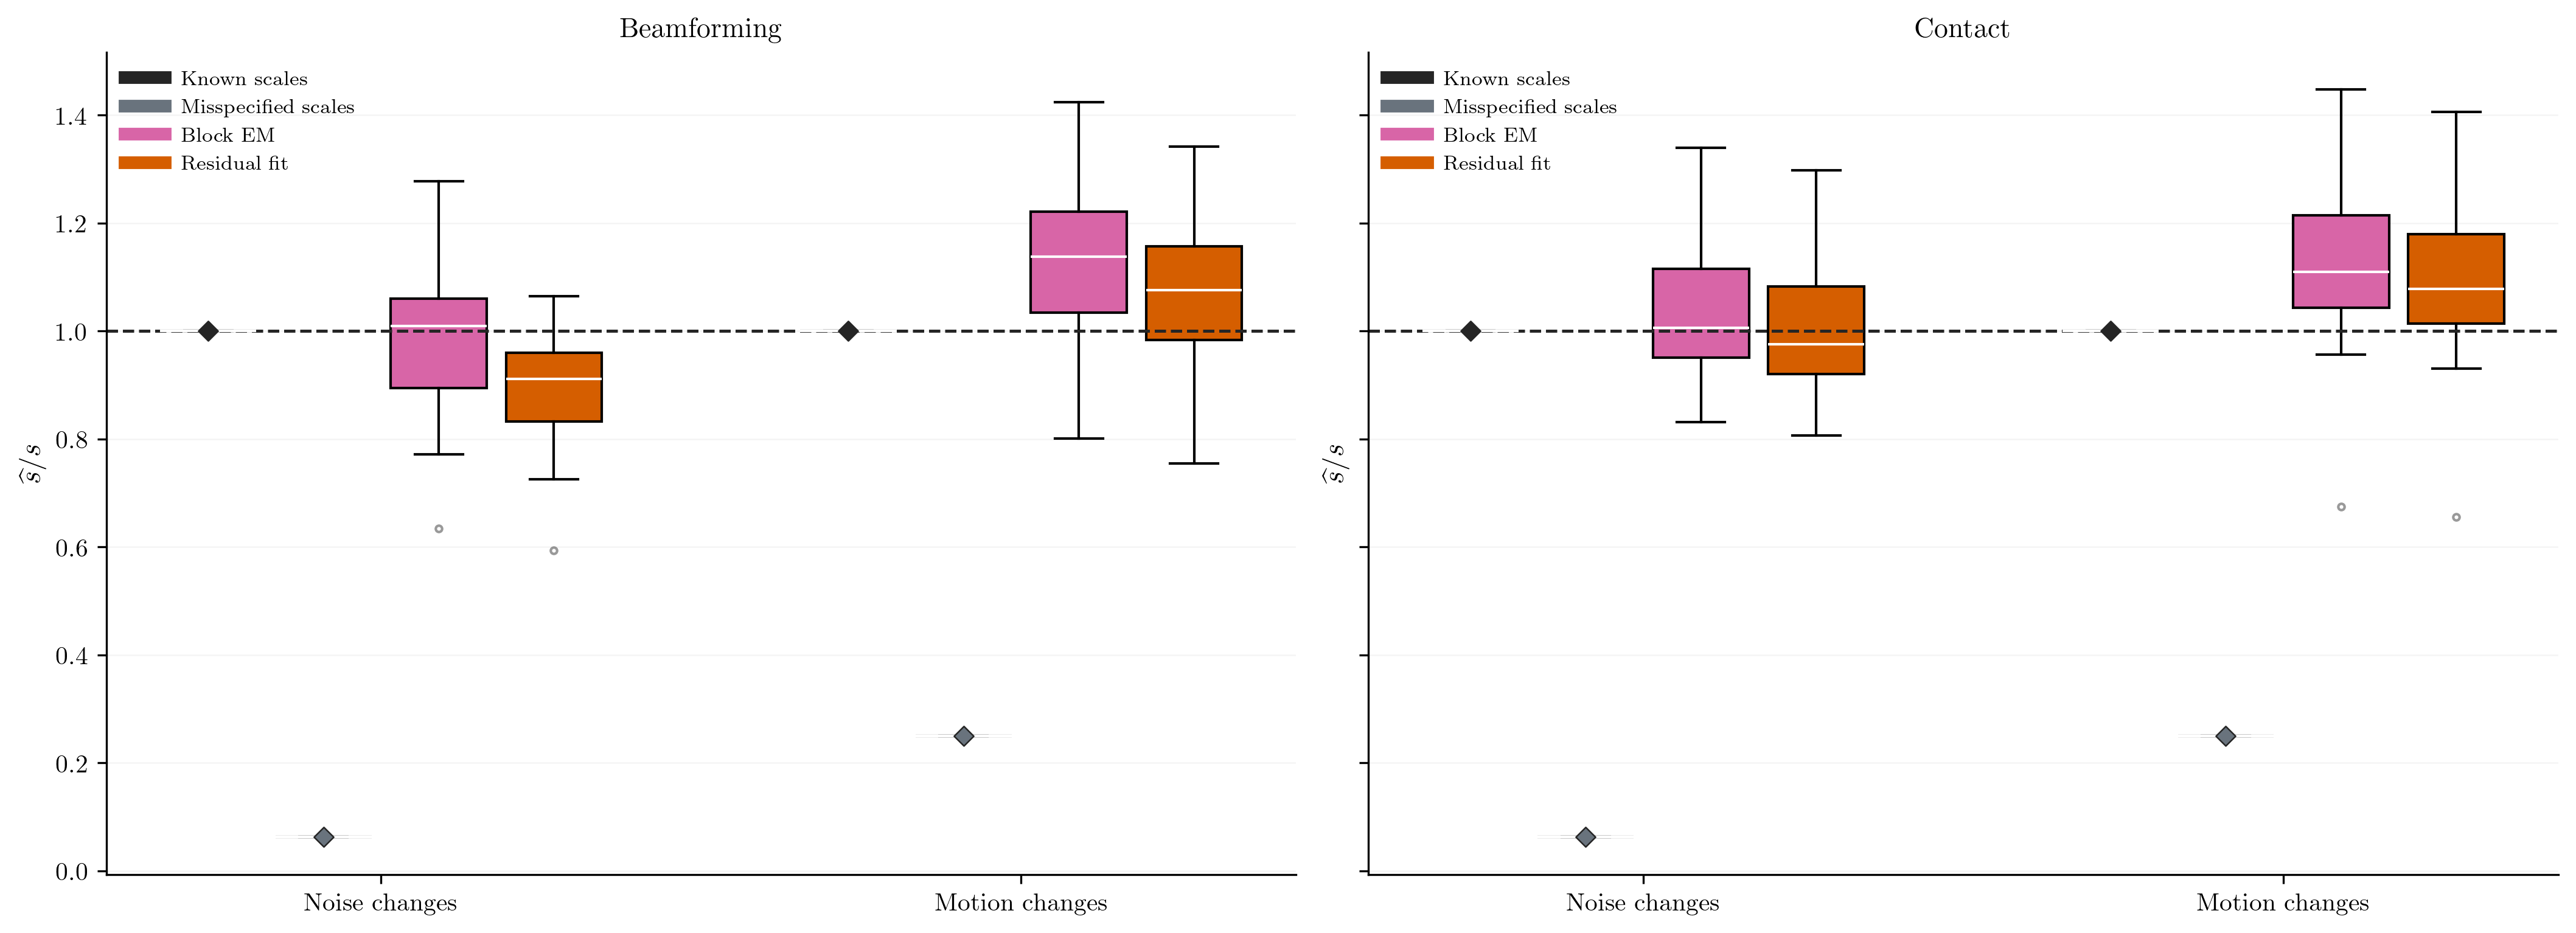

In [15]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (14, 5)
data = load_audit_data(ROOT, 'reliability')

frame = data['adaptation']
models = list(frame.model.drop_duplicates())
fig, axes = plt.subplots(1, len(models), figsize=FIGSIZE, layout='constrained', squeeze=False, sharey=True, dpi=DPI)
colors = {'known': BLACK, 'misspecified': GREY, 'block_em': PINK, 'residual': ORANGE}
for ax, model in zip(axes.ravel(), models):
    g = frame[frame.model.eq(model)]
    g = g[g.block.eq(g.block.max())]
    methods = [m for m in ['known', 'misspecified', 'block_em', 'residual'] if m in set(g.method)]
    changes = list(g.change.drop_duplicates())
    for j, method in enumerate(methods):
        arrays = []
        for change in changes:
            h = g[g.method.eq(method) & g.change.eq(change)]
            arrays.append((h.fitted_s / h.true_s).to_numpy())
        positions = np.arange(len(changes)) + (j - (len(methods) - 1) / 2) * 0.18
        boxes = ax.boxplot(arrays, positions=positions, widths=0.15, patch_artist=True, manage_ticks=False, medianprops={'color': 'white'}, flierprops={'markersize': 2.5, 'alpha': 0.4})
        for box in boxes['boxes']:
            box.set_facecolor(colors[method])
        for position, values in zip(positions, arrays):
            if len(values) and np.ptp(values) == 0:
                ax.scatter(position, values[0], marker='D', s=30, color=colors[method], edgecolors=BLACK, lw=0.6, zorder=5)
    ax.axhline(1, color=BLACK, ls='--', lw=1.2)
    ax.set(xticks=np.arange(len(changes)), xticklabels=[text_label(v) for v in changes], ylabel='$\\widehat s/s$', title=text_label(model))
    ax.legend(handles=[Line2D([0], [0], color=colors[m], lw=5, label=METHODS[m]) for m in methods], frameon=False, fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.13, linewidth=0.6)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'B7b_C6b_scale_adaptation.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## C5. Keep changed mechanics and sensors visible

The ideal plant independently solves its KKT system. Maintained bilateral contact, known damping, negligible inertia and the noise model are assumptions of the conditional likelihood. Friction, detachment, anisotropic mobility and position-differenced velocity noise change that model.

Known anisotropic damping requires the scaled-coordinate projection and correctly transformed noise. Differencing independent noisy positions produces temporally correlated velocity errors. Those mechanical and covariance identities are checked directly; their mismatched counterparts remain diagnostic experiments, not claimed extensions of the isotropic theorem.

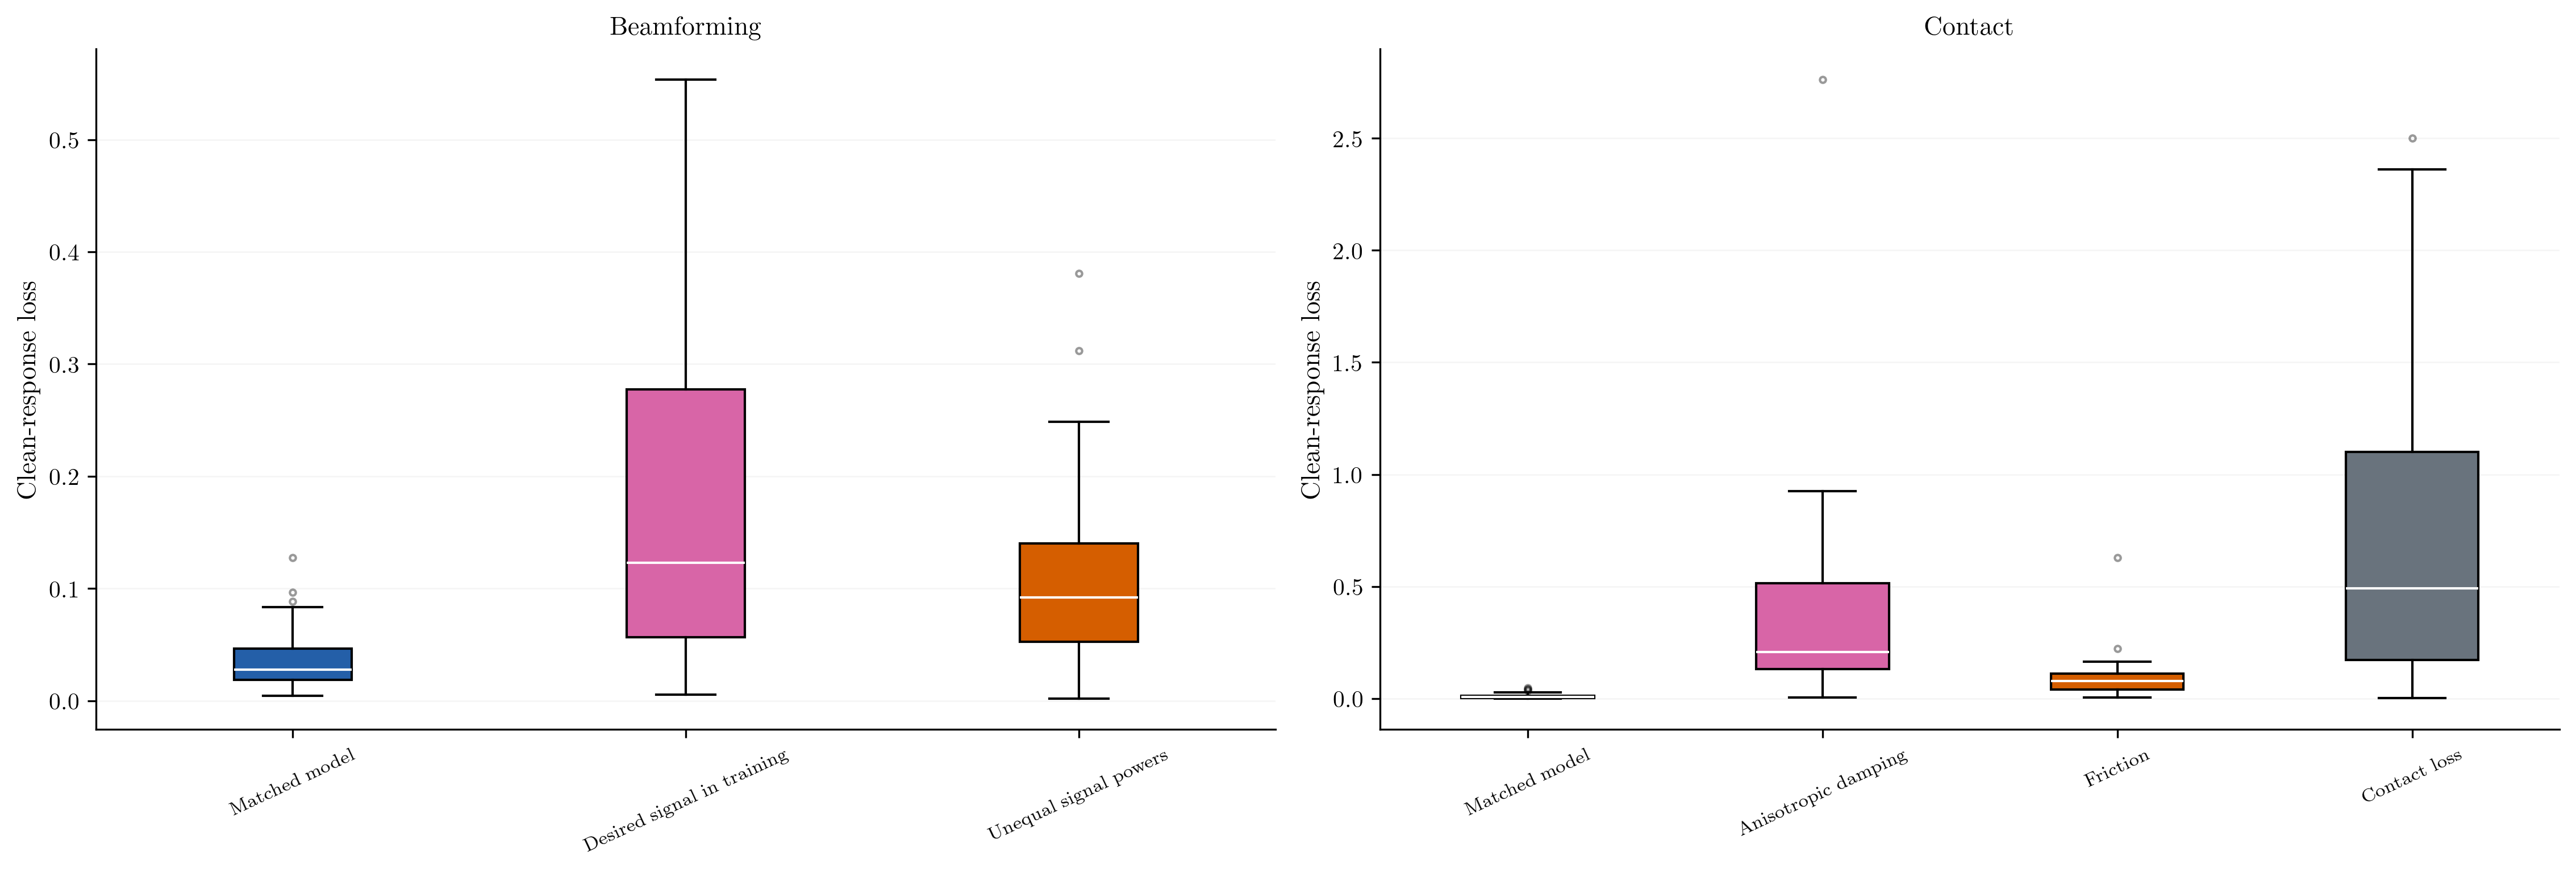

In [16]:
# Change these values for this figure only.
DPI = 300
FIGSIZE = (15, 5)
data = load_audit_data(ROOT, 'reliability')

frame = data['mismatch']
models = list(frame.model.drop_duplicates())
fig, axes = plt.subplots(1, len(models), figsize=FIGSIZE, layout='constrained', squeeze=False, dpi=DPI)
for ax, model in zip(axes.ravel(), models):
    group = frame[frame.model.eq(model)]
    names = list(group.stress.drop_duplicates())
    arrays = [group[group.stress.eq(name)].groupby('episode').response_loss.mean().to_numpy() for name in names]
    boxes = ax.boxplot(arrays, tick_labels=[text_label(name) for name in names], patch_artist=True, medianprops={'color': 'white'}, flierprops={'markersize': 2.5, 'alpha': 0.4})
    for j, box in enumerate(boxes['boxes']):
        box.set_facecolor((BLUE, PINK, ORANGE, GREY)[j % 4])
    ax.set(ylabel='Clean-response loss', title=text_label(model))
    ax.tick_params(axis='x', labelrotation=25, labelsize=8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.13, linewidth=0.6)

# This file is separate from the frozen published figure and numerical data.
fig.savefig(EDITABLE_OUTPUT / 'C5_model_mismatch.pdf', dpi=DPI, bbox_inches=None)
plt.show()


## S1. Computational feasibility has a defined scope

The existing [scaling panels](../results/implementation_audit/paper/figures/S1_native_scaling.pdf) separate parameter corrections, eigenspaces, native moments and optional uncertainty reports. Native rank-one/codimension-one calculations do not validate arbitrary-rank integration. Serial timing runs have their own fixed streams, warm-up and repetition budget; reference-quality integration has separate accuracy settings.

The main applications and their raw results are retained. Read the [results note](../results/implementation_audit/findings.md), [claim manifest](../results/implementation_audit/claim_manifest.json), [audit protocol](../docs/implementation_guide_audit.md) and [reproduction commands](../results/implementation_audit/README.md) for numerical tolerances, Monte Carlo precision, limitations and the distinction between passed checks and inconclusive performance comparisons.